# ĐT09 - Phân tích đơn hàng, vận chuyển và thanh toán trên sàn thương mại điện tử

**Trường Đại học Nguyễn Tất Thành - Khoa Công nghệ thông tin**  
Báo cáo cuối kỳ học phần: Kỹ thuật Công nghệ thông tin 1  
Nhóm thực hiện: Nhóm  
Công cụ: Python 3.12, Pandas, NumPy, Matplotlib, Seaborn (Jupyter Notebook / Google Colab)

---

### Mục tiêu bài làm (theo yêu cầu đề tài ĐT09)
1. Chọn tối thiểu 4 bảng (bài thực hiện trên 7/9 bảng quan hệ), mô tả rõ khóa nối (PK/FK, kiểu quan hệ) và thực hiện join không làm nhân bản bản ghi không mong muốn.
2. Xử lý và làm sạch dữ liệu giao hàng, ngày tháng, số tiền và trạng thái đơn hàng, có ghi nhật ký kiểm tra trước - sau.
3. Tính doanh số theo tháng, nhóm ngành hàng, phương thức thanh toán và thời gian giao hàng.
4. Trực quan hóa nhiều góc nhìn và diễn giải kết quả dựa trên số liệu thực tế.

## 1. Giới thiệu nguồn dữ liệu, cấu trúc khóa nối và thiết lập môi trường

### 1.1. Thông tin nguồn dữ liệu
| Mục | Thông tin |
|---|---|
| Tên bộ dữ liệu | *Brazilian E-Commerce Public Dataset by Olist* |
| Tổ chức phát hành | Olist Store (Brazil), công bố trên Kaggle |
| Đường dẫn gốc | https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce |
| Quy mô gốc | 9 tệp CSV quan hệ, khoảng 100.000 đơn hàng thực (giai đoạn 09/2016 - 10/2018), đã ẩn danh |
| Đơn vị tiền tệ | Real Brazil (R\$) |
| Giấy phép | CC BY-NC-SA 4.0 (dùng cho học tập, phi thương mại) |

### 1.2. Danh mục 7 bảng được chọn và sơ đồ khóa nối
Trong 9 tệp CSV của bộ dữ liệu gốc, bài sử dụng 7 bảng liên quan trực tiếp đến đơn hàng, ngành hàng, thanh toán, vận chuyển và đánh giá (không đưa `olist_geolocation_dataset.csv` và `olist_sellers_dataset.csv` vào nối vì đề tài không yêu cầu phân tích tọa độ bản đồ hay đánh giá riêng từng nhà bán).

| STT | Tệp CSV (tên biến) | Khóa chính (PK) / Khóa ngoại (FK) | Quan hệ | Các trường chính sử dụng |
|:-:|:---|:---|:---|:---|
| 1 | `olist_orders_dataset.csv` (`orders`) | `order_id` (PK), `customer_id` (FK) | Bảng trung tâm (1 dòng = 1 đơn hàng) | `order_status`, 5 mốc thời gian (mua, duyệt, giao ĐVVC, giao khách, ngày hẹn) |
| 2 | `olist_order_items_dataset.csv` (`items`) | (`order_id`, `order_item_id`) (PK), `product_id` (FK) | `orders` 1 - N `items` | `order_item_id`, `product_id`, `seller_id`, `price`, `freight_value`, `shipping_limit_date` |
| 3 | `olist_order_payments_dataset.csv` (`payments`) | (`order_id`, `payment_sequential`) (PK) | `orders` 1 - N `payments` | `payment_sequential`, `payment_type`, `payment_installments`, `payment_value` |
| 4 | `olist_customers_dataset.csv` (`customers`) | `customer_id` (PK), `customer_unique_id` | `customers` 1 - 1 `orders` (theo `customer_id`) | `customer_unique_id`, `customer_state`, `customer_city` |
| 5 | `olist_products_dataset.csv` (`products`) | `product_id` (PK), `product_category_name` (FK) | `products` 1 - N `items` | `product_category_name`, `product_weight_g` |
| 6 | `product_category_name_translation.csv` (`translation`) | `product_category_name` (PK) | `translation` 1 - N `products` | `product_category_name_english` |
| 7 | `olist_order_reviews_dataset.csv` (`reviews`) | `review_id` (PK), `order_id` (FK) | `orders` 1 - N `reviews` (khử trùng về 1 - 1) | `order_id`, `review_score`, `review_creation_date`, `review_answer_timestamp` |

Lưu ý: Các tệp CSV gốc trong thư mục `archive/` được giữ nguyên; toàn bộ quá trình làm sạch chạy trên bản sao trong bộ nhớ. Đoạn code bên dưới tự nhận diện đường dẫn dữ liệu khi chạy trên máy (`../archive`) lẫn trên Google Colab (`/content/archive`, `/content`).

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

# Tìm thư mục chứa 9 tệp CSV (chạy trên máy: ../archive ; chạy trên Colab: đặt các tệp vào thư mục archive)
for cand in ["../archive", "archive", "/content/archive", "/content"]:
    if os.path.exists(os.path.join(cand, "olist_orders_dataset.csv")):
        DATA = cand
        break
else:
    raise FileNotFoundError("Không tìm thấy olist_orders_dataset.csv - hãy kiểm tra thư mục dữ liệu")

OUT_FIG, OUT_DATA, OUT_TAB = "hinh", "du_lieu_xu_ly", "bang_ket_qua"
for d in (OUT_FIG, OUT_DATA, OUT_TAB):
    os.makedirs(d, exist_ok=True)

def luu_hinh(ten):
    plt.savefig(f"{OUT_FIG}/{ten}.png", dpi=150, bbox_inches="tight")

KQ = {}   # nơi gom các chỉ số chính để đưa vào báo cáo
print("Thư mục dữ liệu:", DATA)

Thư mục dữ liệu: ../archive


## 2. Đọc dữ liệu và khám phá ban đầu
Đọc 7 tệp CSV bằng `pd.read_csv`, kiểm tra số dòng, số cột, số ô thiếu (`NaN`), dòng trùng hoàn toàn và kiểu dữ liệu ban đầu của bảng `orders`.

In [2]:
files = {
    "orders":      "olist_orders_dataset.csv",
    "items":       "olist_order_items_dataset.csv",
    "payments":    "olist_order_payments_dataset.csv",
    "customers":   "olist_customers_dataset.csv",
    "products":    "olist_products_dataset.csv",
    "reviews":     "olist_order_reviews_dataset.csv",
    "translation": "product_category_name_translation.csv",
}
raw = {k: pd.read_csv(os.path.join(DATA, v)) for k, v in files.items()}

tong_quan = pd.DataFrame.from_dict({
    k: {
        "số dòng": df.shape[0],
        "số cột": df.shape[1],
        "ô thiếu": int(df.isna().sum().sum()),
        "dòng trùng hoàn toàn": int(df.duplicated().sum()),
        "bộ nhớ (MB)": round(df.memory_usage(deep=True).sum() / 1e6, 1),
    } for k, df in raw.items()
}, orient="index")
tong_quan.to_csv(f"{OUT_TAB}/00_tong_quan_nguon_du_lieu.csv", encoding="utf-8-sig")
tong_quan

,số dòng,số cột,ô thiếu,dòng trùng hoàn toàn,bộ nhớ (MB)
orders,99441,8,4908,0,55.50
items,112650,7,0,0,37.70
payments,103886,5,0,0,17.00
customers,99441,5,0,0,27.90
products,32951,9,2448,0,6.60
reviews,99224,7,145903,0,41.00
translation,71,2,0,0,0.00


In [3]:
for k in ["orders", "items", "payments", "customers"]:
    print(f"===== {k} =====")
    display(raw[k].head(3))
print("===== Kiểu dữ liệu của bảng orders (trước khi xử lý) =====")
raw["orders"].dtypes.to_frame("dtype")

===== orders =====


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


===== items =====


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87


===== payments =====


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71


===== customers =====


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP


===== Kiểu dữ liệu của bảng orders (trước khi xử lý) =====


,dtype
order_id,str
customer_id,str
order_status,str
order_purchase_timestamp,str
order_approved_at,str
order_delivered_carrier_date,str
order_delivered_customer_date,str
order_estimated_delivery_date,str


**Nhận xét:**
- Về quy mô: `orders` có 99.441 dòng, `items` có 112.650 dòng, `payments` có 103.886 dòng, `customers` có 99.441 dòng, `products` có 32.951 dòng, `reviews` có 99.224 dòng và `translation` có 71 dòng.
- Cả 7 bảng đều không có dòng nào bị trùng hoàn toàn (0 dòng trùng).
- Cả 5 cột thời gian trong `orders` đang ở kiểu chuỗi (`object`/`str`), cần chuyển sang `datetime64` trước khi tính thời gian giao hàng.
- Bảng `orders` có 4.908 ô thiếu ở các mốc duyệt đơn, giao cho đơn vị vận chuyển và giao cho khách, chủ yếu thuộc các đơn chưa giao xong hoặc đã hủy. Bảng `reviews` có 145.903 ô thiếu nhưng nằm ở 2 cột nội dung bình luận (cột `review_score` đầy đủ 100%); bảng `products` thiếu tên ngành hàng ở 610 sản phẩm.

## 3. Làm sạch dữ liệu
Quy trình kiểm tra và làm sạch gồm 5 bước, có lưu nhật ký vào biến `log`:
1. Ép kiểu 5 cột ngày tháng của `orders` và kiểm tra định dạng.
2. Kiểm tra dữ liệu thiếu theo từng trạng thái đơn (`order_status`) và rà soát logic thứ tự thời gian.
3. Làm sạch các bảng `payments`, `items`, `products` (kèm bổ sung bản dịch còn thiếu), kiểm tra khóa của `customers` và khử trùng `order_id` ở bảng `reviews`.
4. Khảo sát ngoại lệ (Outliers) của 3 biến số tiền theo quy tắc IQR.
5. Tổng hợp nhật ký làm sạch và bảng đối chiếu trước - sau xử lý.

In [4]:
log = []   # nhật ký làm sạch: bảng / vấn đề / số dòng ảnh hưởng / cách xử lý

orders = raw["orders"].copy()
cot_ngay = [c for c in orders.columns if c.endswith(("_at", "_date", "_timestamp"))]
thieu_truoc = orders[cot_ngay].isna().sum()

for c in cot_ngay:
    orders[c] = pd.to_datetime(orders[c], errors="coerce")
thieu_sau = orders[cot_ngay].isna().sum()
print("Số ô thiếu của các cột ngày trước/sau khi ép kiểu (phải bằng nhau, tức không sinh NaT mới):")
print(pd.DataFrame({"trước": thieu_truoc, "sau": thieu_sau}))
log.append(["orders", "5 cột ngày đang là chuỗi (str/object)", len(orders), "ép sang datetime64 bằng pd.to_datetime (mỗi cột 99.441 giá trị)"])

# --- Thiếu dữ liệu theo trạng thái đơn ---
thieu_tt = (orders.assign(thieu_ngay_giao=orders.order_delivered_customer_date.isna())
                  .groupby("order_status")
                  .agg(so_don=("order_id", "count"), thieu_ngay_giao_khach=("thieu_ngay_giao", "sum")))
display(thieu_tt)

# --- Kiểm tra logic thời gian ---
dg = orders.order_status.eq("delivered")
kiem_tra = {
    "delivered nhưng thiếu ngày giao cho khách": int((dg & orders.order_delivered_customer_date.isna()).sum()),
    "có ngày giao cho khách nhưng trạng thái != delivered": int((~dg & orders.order_delivered_customer_date.notna()).sum()),
    "ngày giao cho khách < ngày mua": int((orders.order_delivered_customer_date < orders.order_purchase_timestamp).sum()),
    "ngày giao cho ĐVVC < ngày mua": int((orders.order_delivered_carrier_date < orders.order_purchase_timestamp).sum()),
    "ngày giao cho khách < ngày giao cho ĐVVC": int((orders.order_delivered_customer_date < orders.order_delivered_carrier_date).sum()),
    "ngày duyệt < ngày mua": int((orders.order_approved_at < orders.order_purchase_timestamp).sum()),
}
kiem_tra = pd.Series(kiem_tra, name="số đơn")
display(kiem_tra.to_frame())

log.append(["orders", "delivered nhưng thiếu ngày giao thực tế", kiem_tra.iloc[0],
            "giữ đơn trong phân tích doanh thu, loại khỏi phân tích thời gian giao hàng"])
log.append(["orders", "đơn chưa/không hoàn tất (shipped, canceled, ...)", int((~dg).sum()),
            "không tính vào doanh thu; chỉ phân tích đơn delivered"])
log.append(["orders", "khóa order_id trùng", int(orders.order_id.duplicated().sum()), "không có - khóa chính hợp lệ"])

Số ô thiếu của các cột ngày trước/sau khi ép kiểu (phải bằng nhau, tức không sinh NaT mới):
                               trước   sau
order_purchase_timestamp           0     0
order_approved_at                160   160
order_delivered_carrier_date    1783  1783
order_delivered_customer_date   2965  2965
order_estimated_delivery_date      0     0


,so_don,thieu_ngay_giao_khach
order_status,,
approved,2,2
canceled,625,619
created,5,5
delivered,96478,8
invoiced,314,314
processing,301,301
shipped,1107,1107
unavailable,609,609


,số đơn
delivered nhưng thiếu ngày giao cho khách,8
có ngày giao cho khách nhưng trạng thái != delivered,6
ngày giao cho khách < ngày mua,0
ngày giao cho ĐVVC < ngày mua,166
ngày giao cho khách < ngày giao cho ĐVVC,23
ngày duyệt < ngày mua,0


**Nhận xét về bảng `orders`:**
- Sau khi ép kiểu bằng `pd.to_datetime(..., errors="coerce")`, số ô thiếu trước và sau ở cả 5 cột đều giữ nguyên (0, 160, 1.783, 2.965 và 0), nghĩa là không có giá trị ngày nào bị lỗi định dạng.
- Trong 2.965 đơn thiếu ngày giao cho khách, có 2.957 đơn thuộc các trạng thái chưa giao xong hoặc đã hủy (`shipped`, `canceled`, `unavailable`, `invoiced`, `processing`, `created`, `approved`). Đây là thiếu hợp lý theo trạng thái đơn nên không xóa hay điền giá trị thay thế. Riêng 8 đơn có trạng thái `delivered` nhưng thiếu ngày giao thực tế sẽ được giữ khi tính doanh thu và loại khỏi phần tính thời gian giao hàng.
- Không có đơn nào bị ghi nhận ngày giao khách hoặc ngày duyệt sớm hơn ngày đặt hàng (0 đơn). Có 166 đơn ghi ngày giao cho ĐVVC trước ngày mua và 23 đơn ghi khách nhận trước khi ĐVVC lấy hàng; các chặng trung gian bị âm này sẽ được xử lý ở mục 5.

In [5]:
# ---------------- payments ----------------
pay = raw["payments"].copy()
n0 = len(pay)
print("Phương thức thanh toán:\n", pay.payment_type.value_counts().to_string())
print("\nSố dòng payment_value = 0:", int((pay.payment_value == 0).sum()),
      "| payment_installments = 0:", int((pay.payment_installments == 0).sum()))
display(pay[pay.payment_type == "not_defined"])

# 3 dòng 'not_defined' đều thuộc đơn bị hủy, giá trị 0  ->  loại bỏ
so_nd = int((pay.payment_type == "not_defined").sum())
pay = pay[pay.payment_type != "not_defined"].copy()
log.append(["payments", "payment_type = not_defined (giá trị 0, đơn hủy)", so_nd, "loại bỏ các dòng này"])

# số kỳ trả góp = 0 là không hợp lệ -> đưa về 1 (thanh toán một lần)
so_0 = int((pay.payment_installments == 0).sum())
pay["payment_installments"] = pay.payment_installments.clip(lower=1)
log.append(["payments", "payment_installments = 0", so_0, "gán = 1 (trả một lần)"])
log.append(["payments", "payment_value = 0 (voucher)", int((pay.payment_value == 0).sum()), "giữ nguyên - voucher 0đ không ảnh hưởng tổng tiền"])

# ---------------- items ----------------
items = raw["items"].copy()
print("\nTrùng khóa (order_id, order_item_id):", int(items.duplicated(["order_id", "order_item_id"]).sum()))
print("price <= 0:", int((items.price <= 0).sum()), "| freight_value < 0:", int((items.freight_value < 0).sum()))
items["shipping_limit_date"] = pd.to_datetime(items.shipping_limit_date, errors="coerce")
log.append(["items", "price <= 0 hoặc freight < 0", int(((items.price <= 0) | (items.freight_value < 0)).sum()), "không có"])
log.append(["items", "freight_value = 0 (miễn phí vận chuyển)", int((items.freight_value == 0).sum()), "giữ nguyên - là chương trình free ship thật"])

# ---------------- products + dịch tên ngành hàng ----------------
prod = raw["products"].copy()
trans = raw["translation"].copy()
thieu_cat = int(prod.product_category_name.isna().sum())
chua_dich = sorted(set(prod.product_category_name.dropna()) - set(trans.product_category_name))
print("\nSản phẩm thiếu tên ngành hàng:", thieu_cat)
print("Ngành hàng chưa có trong bảng dịch:", chua_dich)

# bổ sung thủ công 2 ngành còn thiếu bản dịch
trans = pd.concat([trans, pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_food_preparers"]})], ignore_index=True)
prod = prod.merge(trans, on="product_category_name", how="left", validate="many_to_one")
prod["category_en"] = prod.product_category_name_english.fillna("unknown")
log.append(["products", "thiếu product_category_name", thieu_cat, "gán nhãn 'unknown'"])
log.append(["products", "ngành hàng chưa có bản dịch", len(chua_dich), "bổ sung thủ công vào bảng dịch"])

# ---------------- customers ----------------
cus = raw["customers"].copy()
print("\ncustomer_id trùng:", int(cus.customer_id.duplicated().sum()),
      "| customer_unique_id duy nhất:", cus.customer_unique_id.nunique(), "/", len(cus))
log.append(["customers", "customer_id trùng", int(cus.customer_id.duplicated().sum()),
            "không có; lưu ý customer_id là mã theo đơn, customer_unique_id mới là khách thật"])

# ---------------- reviews ----------------
rev = raw["reviews"].copy()
for c in ["review_creation_date", "review_answer_timestamp"]:
    rev[c] = pd.to_datetime(rev[c], errors="coerce")
so_trung = int(rev.order_id.duplicated().sum())
rev = rev.sort_values("review_answer_timestamp").drop_duplicates("order_id", keep="last")
log.append(["reviews", "một đơn có nhiều đánh giá (trùng order_id)", so_trung, "giữ đánh giá mới nhất mỗi đơn"])
print("Đơn có nhiều hơn 1 đánh giá:", so_trung, "-> sau xử lý còn", len(rev), "dòng")

Phương thức thanh toán:
 payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3

Số dòng payment_value = 0: 9 | payment_installments = 0: 2


,order_id,payment_sequential,payment_type,payment_installments,payment_value
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.00
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.00
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.00



Trùng khóa (order_id, order_item_id): 0
price <= 0: 0 | freight_value < 0: 0

Sản phẩm thiếu tên ngành hàng: 610
Ngành hàng chưa có trong bảng dịch: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']



customer_id trùng:

 0 | customer_unique_id duy nhất: 96096 / 99441


Đơn có nhiều hơn 1 đánh giá: 551 -> sau xử lý còn 98673 dòng


,biến,trung vị,trung bình,P99,max,ngưỡng IQR,số ngoại lệ,% ngoại lệ
0,price (giá hàng),74.99,120.65,890.00,"6,735.00",277.40,8427,7.48
1,freight_value (phí ship),16.26,19.99,84.52,409.68,33.25,11613,10.31
2,payment_value (tiền thanh toán),100.00,154.10,"1,039.92","13,664.08",344.40,7981,7.68


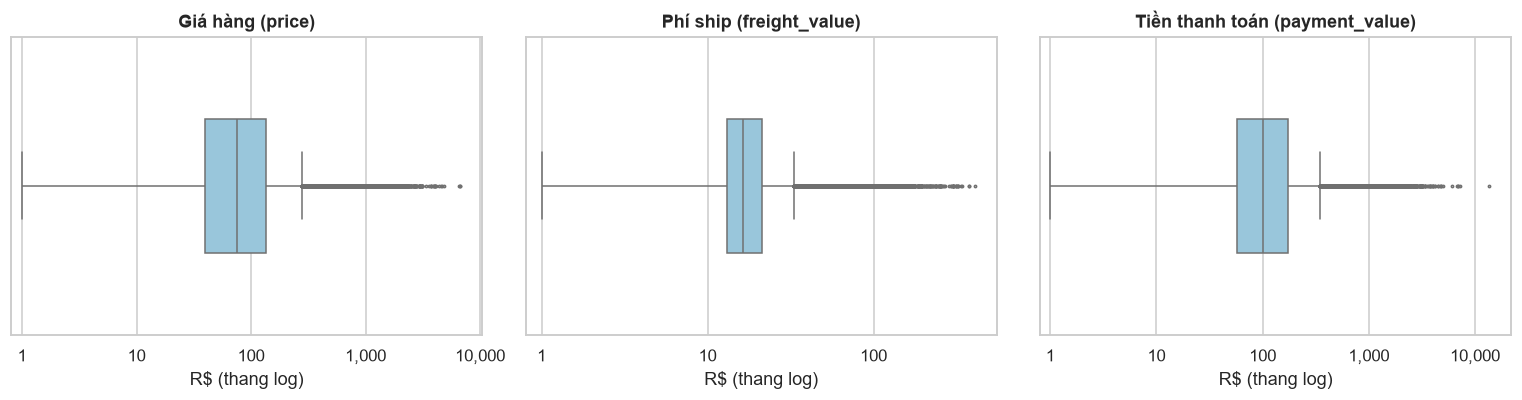

In [6]:
def iqr_outlier(s):
    q1, q3 = s.quantile([.25, .75])
    gioi_han = q3 + 1.5 * (q3 - q1)
    return int((s > gioi_han).sum()), gioi_han

rows = []
for ten, s in [("price (giá hàng)", items.price),
               ("freight_value (phí ship)", items.freight_value),
               ("payment_value (tiền thanh toán)", pay.payment_value)]:
    n, gh = iqr_outlier(s)
    rows.append([ten, s.median(), s.mean(), s.quantile(.99), s.max(), gh, n, n / len(s) * 100])
out_tab = pd.DataFrame(rows, columns=["biến", "trung vị", "trung bình", "P99", "max", "ngưỡng IQR", "số ngoại lệ", "% ngoại lệ"])
display(out_tab)
out_tab.to_csv(f"{OUT_TAB}/01_ngoai_le_so_tien.csv", index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, (ten, s) in zip(ax, [("Giá hàng (price)", items.price), ("Phí ship (freight_value)", items.freight_value),
                              ("Tiền thanh toán (payment_value)", pay.payment_value)]):
    sns.boxplot(x=s.clip(lower=1), ax=a, color="#8ecae6", fliersize=1.5, width=0.45)
    a.set_xscale("log"); a.set_xlim(left=0.8)
    a.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{int(x):,}" if x >= 1 else f"{x:g}"))
    a.set_title(ten); a.set_xlabel("R$ (thang log)")
plt.tight_layout(); luu_hinh("01_ngoai_le_so_tien"); plt.show()

log.append(["items/payments", "ngoại lệ số tiền theo IQR (price, freight, payment_value)",
            int(out_tab["số ngoại lệ"].sum()),
            "GIỮ LẠI vì là đơn giá trị cao có thật (đồ nội thất, thiết bị); dùng trung vị và thang log khi mô tả"])

**Nhận xét về ngoại lệ số tiền (IQR):**
- Cả 3 biến số tiền đều có phân phối lệch phải mạnh (trung bình cao hơn nhiều so với trung vị):
  - `price`: trung vị 74,99 R\$, trung bình 120,65 R\$, cao nhất 6.735,00 R\$ (7,48% số dòng vượt ngưỡng IQR 277,40 R\$).
  - `freight_value`: trung vị 16,26 R\$, trung bình 19,99 R\$, cao nhất 409,68 R\$ (10,31% vượt ngưỡng IQR 33,25 R\$).
  - `payment_value`: trung vị 100,00 R\$, trung bình 154,10 R\$, cao nhất 13.664,08 R\$ (7,68% vượt ngưỡng IQR 344,41 R\$).
- Các giá trị lớn này là những đơn hàng thật có giá trị cao (đồ nội thất, nhạc cụ, thiết bị gia dụng hoặc đơn nhiều sản phẩm giao đi xa), không phải lỗi nhập liệu. Do đó bài giữ lại toàn bộ ngoại lệ để không làm thiếu doanh thu, đồng thời dùng thêm trung vị và thang đo logarit khi mô tả và vẽ biểu đồ.

In [7]:
log_base = list(log)   # lưu bản gốc giai đoạn làm sạch để tránh nhân bản nếu chạy lại bước sau
log_df = pd.DataFrame(log_base, columns=["Bảng", "Vấn đề phát hiện", "Số dòng/ô ảnh hưởng", "Cách xử lý"])
log_df.to_csv(f"{OUT_TAB}/02_nhat_ky_lam_sach.csv", index=False, encoding="utf-8-sig")

truoc_sau = pd.DataFrame({
    "Trước xử lý": {
        "orders: số cột ngày kiểu datetime": 0,
        "payments: số dòng": len(raw["payments"]),
        "payments: dòng not_defined": so_nd,
        "payments: dòng installments = 0": so_0,
        "reviews: số dòng": len(raw["reviews"]),
        "reviews: đơn có nhiều hơn 1 đánh giá": so_trung,
        "products: thiếu tên ngành hàng (NaN)": thieu_cat,
        "products: ngành hàng chưa có bản dịch": len(chua_dich),
    },
    "Sau xử lý": {
        "orders: số cột ngày kiểu datetime": int(sum(pd.api.types.is_datetime64_any_dtype(orders[c]) for c in cot_ngay)),
        "payments: số dòng": len(pay),
        "payments: dòng not_defined": int((pay.payment_type == "not_defined").sum()),
        "payments: dòng installments = 0": int((pay.payment_installments == 0).sum()),
        "reviews: số dòng": len(rev),
        "reviews: đơn có nhiều hơn 1 đánh giá": int(rev.order_id.duplicated().sum()),
        "products: thiếu tên ngành hàng (NaN)": int(prod.category_en.isna().sum()),
        "products: ngành hàng chưa có bản dịch": int((prod.product_category_name.notna() & prod.product_category_name_english.isna()).sum()),
    },
})
truoc_sau["Thay đổi"] = truoc_sau["Sau xử lý"] - truoc_sau["Trước xử lý"]
display(log_df)
display(truoc_sau)
truoc_sau.to_csv(f"{OUT_TAB}/03_truoc_sau_lam_sach.csv", encoding="utf-8-sig")

,Bảng,Vấn đề phát hiện,Số dòng/ô ảnh hưởng,Cách xử lý
0,orders,5 cột ngày đang là chuỗi (str/object),99441,ép sang datetime64 bằng pd.to_datetime (mỗi cộ...
1,orders,delivered nhưng thiếu ngày giao thực tế,8,"giữ đơn trong phân tích doanh thu, loại khỏi p..."
2,orders,"đơn chưa/không hoàn tất (shipped, canceled, ...)",2963,không tính vào doanh thu; chỉ phân tích đơn de...
3,orders,khóa order_id trùng,0,không có - khóa chính hợp lệ
4,payments,"payment_type = not_defined (giá trị 0, đơn hủy)",3,loại bỏ các dòng này
5,payments,payment_installments = 0,2,gán = 1 (trả một lần)
6,payments,payment_value = 0 (voucher),6,giữ nguyên - voucher 0đ không ảnh hưởng tổng tiền
7,items,price <= 0 hoặc freight < 0,0,không có
8,items,freight_value = 0 (miễn phí vận chuyển),383,giữ nguyên - là chương trình free ship thật
9,products,thiếu product_category_name,610,gán nhãn 'unknown'


,Trước xử lý,Sau xử lý,Thay đổi
orders: số cột ngày kiểu datetime,0,5,5
payments: số dòng,103886,103883,-3
payments: dòng not_defined,3,0,-3
payments: dòng installments = 0,2,0,-2
reviews: số dòng,99224,98673,-551
reviews: đơn có nhiều hơn 1 đánh giá,551,0,-551
products: thiếu tên ngành hàng (NaN),610,0,-610
products: ngành hàng chưa có bản dịch,2,0,-2


## 4. Kết hợp bảng (Merge / Join) và kiểm soát nhân bản bản ghi

### 4.1. Vấn đề nhân bản bản ghi khi nối trực tiếp
Trong dữ liệu Olist, cả `order_items` và `order_payments` đều có quan hệ 1 - N với `orders` theo khóa `order_id`. Nếu nối thẳng ba bảng theo `order_id`, một đơn hàng có M sản phẩm và N lần thanh toán sẽ bị ghép chéo thành M x N dòng, làm giá sản phẩm bị lặp N lần còn số tiền thanh toán bị lặp M lần.

### 4.2. Cách nối bảng tránh nhân bản
1. Gộp trước khi nối (`groupby` + `agg`): thu gọn `items` thành `items_agg` (1 dòng mỗi đơn) và thu gọn `payments` thành `pay_agg` cùng `main_type` (cộng tổng tiền theo từng cặp `order_id`, `payment_type` rồi lấy phương thức có tổng tiền cao nhất của mỗi đơn).
2. Dùng `LEFT JOIN` kèm tham số `validate` (`one_to_one` / `many_to_one`):
   - Bảng cấp đơn hàng `df_order`: nối từ `orders` sang `customers`, `items_agg`, `pay_agg`, `main_type` và `rev_agg`.
   - Bảng cấp sản phẩm `df_item`: nối từ `items` sang `orders` và `products` (đã ghép bảng dịch) để phục vụ thống kê theo ngành hàng.
3. Kiểm tra lại bằng `assert` (số dòng sau nối phải bằng số dòng bảng gốc, `order_id` không trùng) và đối chiếu tổng tiền trước - sau khi nối.

Dưới đây là phần chạy thử để so sánh trực tiếp giữa cách nối sai và cách nối đúng:

In [8]:
# Cách nối "ngây thơ": nối thẳng orders - items - payments theo order_id
naive = orders.merge(items, on="order_id", how="inner").merge(pay, on="order_id", how="inner")

# Cách đúng (cùng tập đơn để so sánh công bằng): gộp từng bảng về 1 dòng/đơn rồi mới nối
p_gop = pay.groupby("order_id", as_index=False).payment_value.sum()
i_gop = items.groupby("order_id", as_index=False).price.sum()
dung_don = orders[["order_id"]].merge(i_gop, on="order_id").merge(p_gop, on="order_id")

so_sanh = pd.DataFrame({
    "Số dòng": [len(naive), len(dung_don)],
    "Số đơn (order_id duy nhất)": [naive.order_id.nunique(), dung_don.order_id.nunique()],
    "Tổng price (R$)": [naive.price.sum(), dung_don.price.sum()],
    "Tổng payment_value (R$)": [naive.payment_value.sum(), dung_don.payment_value.sum()],
}, index=["Nối trực tiếp (sai)", "Gộp theo đơn rồi mới nối (đúng)"])
so_sanh["payment_value chênh so với đúng (%)"] = (so_sanh["Tổng payment_value (R$)"] / so_sanh.iloc[1, 3] - 1) * 100
so_sanh["price chênh so với đúng (%)"] = (so_sanh["Tổng price (R$)"] / so_sanh.iloc[1, 2] - 1) * 100
display(so_sanh)
so_sanh.to_csv(f"{OUT_TAB}/04_so_sanh_noi_sai_dung.csv", encoding="utf-8-sig")

KQ["noi_sai_pay_pct"] = round(float(so_sanh.iloc[0, 4]), 2)
KQ["noi_sai_price_pct"] = round(float(so_sanh.iloc[0, 5]), 2)
KQ["noi_sai_so_dong"] = int(len(naive))
KQ["noi_dung_so_dong"] = int(len(dung_don))
KQ["noi_sai_tong_pay"] = round(float(so_sanh.iloc[0, 3]), 0)
KQ["noi_dung_tong_pay"] = round(float(so_sanh.iloc[1, 3]), 0)

# Ví dụ cụ thể một đơn bị nhân bản
vd = (naive.groupby("order_id").size().sort_values(ascending=False).head(1)).index[0]
ct = naive[naive.order_id == vd]
print(f"Ví dụ: đơn {vd} chỉ có {ct.order_item_id.nunique()} sản phẩm và {ct.payment_sequential.nunique()} lần thanh toán, "
      f"nhưng sau khi nối trực tiếp thành {len(ct)} dòng ({ct.order_item_id.nunique()} x {ct.payment_sequential.nunique()}).")
KQ["vd_don"] = {"order_id": vd, "n_items": int(ct.order_item_id.nunique()), "n_pay": int(ct.payment_sequential.nunique()), "n_dong": int(len(ct))}
display(ct[["order_id", "order_item_id", "price", "payment_sequential", "payment_type", "payment_value"]].head(6))

,Số dòng,Số đơn (order_id duy nhất),Tổng price (R$),Tổng payment_value (R$),payment_value chênh so với đúng (%),price chênh so với đúng (%)
Nối trực tiếp (sai),117601,98665,"14,209,115.34","20,308,134.71",28.16,4.54
Gộp theo đơn rồi mới nối (đúng),98665,98665,"13,591,508.73","15,846,280.17",0.00,0.00


Ví dụ: đơn 895ab968e7bb0d5659d16cd74cd1650c chỉ có 3 sản phẩm và 21 lần thanh toán, nhưng sau khi nối trực tiếp thành 63 dòng (3 x 21).


,order_id,order_item_id,price,payment_sequential,payment_type,payment_value
84420,895ab968e7bb0d5659d16cd74cd1650c,1,12.99,17,voucher,16.70
84421,895ab968e7bb0d5659d16cd74cd1650c,1,12.99,1,voucher,2.61
84422,895ab968e7bb0d5659d16cd74cd1650c,1,12.99,13,voucher,16.70
84423,895ab968e7bb0d5659d16cd74cd1650c,1,12.99,16,voucher,16.70
84424,895ab968e7bb0d5659d16cd74cd1650c,1,12.99,19,voucher,0.24
84425,895ab968e7bb0d5659d16cd74cd1650c,1,12.99,4,voucher,2.61


**Nhận xét thực nghiệm nối bảng:**
- Trên cùng tập 98.665 đơn hàng, cách nối trực tiếp tạo ra 117.601 dòng (dư 18.936 dòng bị nhân bản).
- Tổng `payment_value` bị đội từ 15.846.280 R\$ lên 20.308.135 R\$ (chênh +28,16%), còn tổng `price` bị cộng dư +4,54%.
- Trường hợp rõ nhất là đơn `895ab968e7bb0d5659d16cd74cd1650c`: chỉ có 3 sản phẩm và 21 lượt thanh toán (nhiều phiếu voucher), nhưng sau khi nối trực tiếp đã nhân thành 3 x 21 = 63 dòng.

In [9]:
# --- Bước 1: gộp (aggregate) các bảng "nhiều" về mức 1 dòng / đơn hàng ---
items_agg = (items.groupby("order_id")
                  .agg(n_items=("order_item_id", "size"),
                       n_sellers=("seller_id", "nunique"),
                       item_value=("price", "sum"),
                       freight_value=("freight_value", "sum"))
                  .reset_index())
items_agg["gmv"] = items_agg.item_value + items_agg.freight_value

pay_agg = (pay.groupby("order_id")
              .agg(payment_value=("payment_value", "sum"),
                   n_payment_rows=("payment_sequential", "size"),
                   n_payment_types=("payment_type", "nunique"),
                   max_installments=("payment_installments", "max"))
              .reset_index())
# phương thức chính = cộng tổng tiền theo từng cặp (order_id, payment_type) rồi chọn loại lớn nhất trong đơn
main_type = (pay.groupby(["order_id", "payment_type"], as_index=False)["payment_value"].sum()
                .sort_values(["order_id", "payment_value"], ascending=[True, False])
                .drop_duplicates("order_id")[["order_id", "payment_type"]]
                .rename(columns={"payment_type": "main_payment_type"}))
rev_agg = rev[["order_id", "review_score"]]

# --- Bước 2: nối về bảng orders (mức đơn hàng) bằng LEFT JOIN + validate ---
df_order = (orders
    .merge(cus[["customer_id", "customer_unique_id", "customer_state", "customer_city"]],
           on="customer_id", how="left", validate="many_to_one")
    .merge(items_agg, on="order_id", how="left", validate="one_to_one")
    .merge(pay_agg,   on="order_id", how="left", validate="one_to_one")
    .merge(main_type, on="order_id", how="left", validate="one_to_one")
    .merge(rev_agg,   on="order_id", how="left", validate="one_to_one"))

assert len(df_order) == len(orders), "Join làm thay đổi số đơn hàng!"
assert df_order.order_id.is_unique

# --- Bước 3: bảng mức sản phẩm (1 dòng / sản phẩm trong đơn) để phân tích ngành hàng ---
df_item = (items
    .merge(orders[["order_id", "order_status", "order_purchase_timestamp"]], on="order_id", how="left", validate="many_to_one")
    .merge(prod[["product_id", "category_en", "product_weight_g"]], on="product_id", how="left", validate="many_to_one"))
assert len(df_item) == len(items)

kiem_tra_join = pd.DataFrame({
    "Bảng": ["orders (gốc)", "df_order (sau 5 phép nối)", "items (gốc)", "df_item (sau 2 phép nối)"],
    "Số dòng": [len(orders), len(df_order), len(items), len(df_item)],
})
display(kiem_tra_join)

# --- Bước 4: đối chiếu số tiền giữa các bảng ---
print("Tổng item_value + freight (từ items) :", f"{df_order.gmv.sum():,.2f}")
print("Tổng price + freight (bảng gốc items):", f"{(items.price + items.freight_value).sum():,.2f}")
print("Tổng payment_value (từ df_order)     :", f"{df_order.payment_value.sum():,.2f}")
print("Tổng payment_value (bảng pay đã làm sạch):", f"{pay.payment_value.sum():,.2f}")

print("\nĐơn không có dòng items :", int(df_order.n_items.isna().sum()),
      "->", df_order[df_order.n_items.isna()].order_status.value_counts().to_dict())
print("Đơn không có dòng payments:", int(df_order.payment_value.isna().sum()))
print("Đơn có >1 phương thức thanh toán:", int((df_order.n_payment_types > 1).sum()))
print("Đơn có nhiều hơn 1 sản phẩm   :", int((df_order.n_items > 1).sum()))

,Bảng,Số dòng
0,orders (gốc),99441
1,df_order (sau 5 phép nối),99441
2,items (gốc),112650
3,df_item (sau 2 phép nối),112650


Tổng item_value + freight (từ items) : 15,843,553.24
Tổng price + freight (bảng gốc items): 15,843,553.24
Tổng payment_value (từ df_order)     : 16,008,872.12
Tổng payment_value (bảng pay đã làm sạch): 16,008,872.12

Đơn không có dòng items : 775 -> {'unavailable': 603, 'canceled': 164, 'created': 5, 'invoiced': 2, 'shipped': 1}
Đơn không có dòng payments: 4
Đơn có >1 phương thức thanh toán: 2246
Đơn có nhiều hơn 1 sản phẩm   : 9803


In [10]:
# Đối chiếu: tiền khách trả (payment_value) so với giá hàng + phí ship (gmv) của các đơn delivered
dlv = df_order[df_order.order_status == "delivered"].copy()
cmp_ = dlv.dropna(subset=["gmv", "payment_value"]).copy()
cmp_["lech"] = cmp_.payment_value - cmp_.gmv
khop = (cmp_.lech.abs() <= 0.01).mean() * 100
print(f"{len(cmp_):,} đơn delivered có đủ items + payments")
print(f"Tỷ lệ đơn khớp tuyệt đối (|chênh lệch| <= 0.01): {khop:.2f}%")
print("Thống kê chênh lệch (R$):")
print(cmp_.lech.describe(percentiles=[.01, .05, .5, .95, .99]).round(2).to_string())
print("Tổng gmv =", f"{cmp_.gmv.sum():,.0f}", "| tổng payment =", f"{cmp_.payment_value.sum():,.0f}",
      f"| payment / gmv = {cmp_.payment_value.sum() / cmp_.gmv.sum() * 100:.2f}%")
KQ["khop_payment_gmv_pct"] = round(float(khop), 2)
KQ["payment_over_gmv_pct"] = round(float(cmp_.payment_value.sum() / cmp_.gmv.sum() * 100), 2)

96,477 đơn delivered có đủ items + payments
Tỷ lệ đơn khớp tuyệt đối (|chênh lệch| <= 0.01): 99.60%
Thống kê chênh lệch (R$):
count   96,477.00
mean         0.03
std          1.14
min        -51.62
1%          -0.00
5%          -0.00
50%          0.00
95%          0.00
99%          0.00
max        182.81
Tổng gmv = 15,419,630 | tổng payment = 15,422,462 | payment / gmv = 100.02%


**Nhận xét sau khi nối chuẩn và đối chiếu tiền:**
- Sau 5 phép nối, `df_order` giữ nguyên đúng 99.441 dòng như bảng `orders`; bảng `df_item` sau 2 phép nối giữ nguyên 112.650 dòng như bảng `items`. Tổng `gmv` (15.843.553,24 R\$) và tổng `payment_value` (16.008.872,12 R\$) khớp hoàn toàn với dữ liệu gốc.
- Khi đối chiếu trên 96.477 đơn `delivered` có đủ cả hai bảng, tỷ lệ đơn khớp giữa `payment_value` và `gmv` (sai lệch <= 0,01 R\$) đạt 99,60%; tỷ số tổng thanh toán trên tổng GMV là 100,02%.
- Quy ước dùng cho các phần phân tích sau: chỉ tính trên các đơn có `order_status == "delivered"` (96.478 đơn, chiếm 97,02%); doanh thu hàng hóa tính theo tổng `price` (không gồm phí ship), còn phân tích thanh toán tính theo `payment_value` (gồm cả phí ship).

## 5. Tạo biến phân tích và thao tác Indexing / Filtering
Từ tập đơn `delivered` (`dlv`), tạo thêm các biến cần dùng cho phần phân tích:
- Nhóm biến thời gian giao hàng: `purchase_month`, `delivery_days` (tổng số ngày giao thực tế), `estimated_days` (số ngày hẹn), `approve_hours` (số giờ duyệt đơn), `carrier_days` (thời gian chuẩn bị và bàn giao ĐVVC), `transit_days` (thời gian ĐVVC giao đến khách), `delay_days` (độ trễ theo ngày lịch dùng `.dt.normalize()`), `is_late` và cờ `valid_delivery`.
- Nhóm biến địa lý: gán 27 bang của Brazil vào 5 vùng (Đông Nam, Nam, Trung Tây, Đông Bắc, Bắc).
- Với các chặng trung gian bị âm do ghi nhận ngược mốc thời gian (`carrier_days < 0`: 1.350 đơn; `transit_days < 0`: 23 đơn), đặt giá trị `NaN` riêng cho chặng đó và vẫn giữ nguyên `delivery_days`.
- Cuối mục minh họa 5 thao tác indexing/filtering thông dụng của Pandas gồm `.loc`, `.iloc`, boolean mask, `.query()` kết hợp `.isin()` và cắt lát theo chỉ mục thời gian `DatetimeIndex`.

In [11]:
# ----- Tạo các biến thời gian giao hàng -----
dlv["purchase_month"] = dlv.order_purchase_timestamp.dt.to_period("M").dt.to_timestamp()
dlv["delivery_days"] = (dlv.order_delivered_customer_date - dlv.order_purchase_timestamp).dt.total_seconds() / 86400
dlv["estimated_days"] = (dlv.order_estimated_delivery_date - dlv.order_purchase_timestamp).dt.total_seconds() / 86400
dlv["approve_hours"] = (dlv.order_approved_at - dlv.order_purchase_timestamp).dt.total_seconds() / 3600
dlv["carrier_days"] = (dlv.order_delivered_carrier_date - dlv.order_approved_at).dt.total_seconds() / 86400
dlv["transit_days"] = (dlv.order_delivered_customer_date - dlv.order_delivered_carrier_date).dt.total_seconds() / 86400
# số ngày giao trễ so với ngày hẹn (so sánh theo ngày): > 0 là trễ
dlv["delay_days"] = (dlv.order_delivered_customer_date.dt.normalize() - dlv.order_estimated_delivery_date.dt.normalize()).dt.days
dlv["is_late"] = dlv.delay_days > 0

vung = {**dict.fromkeys(["AC", "AP", "AM", "PA", "RO", "RR", "TO"], "Bắc"),
        **dict.fromkeys(["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"], "Đông Bắc"),
        **dict.fromkeys(["DF", "GO", "MT", "MS"], "Trung Tây"),
        **dict.fromkeys(["ES", "MG", "RJ", "SP"], "Đông Nam"),
        **dict.fromkeys(["PR", "RS", "SC"], "Nam")}
dlv["region"] = dlv.customer_state.map(vung)
print("Bang không gán được vùng:", int(dlv.region.isna().sum()))

# cờ hợp lệ cho phân tích thời gian giao hàng
dlv["valid_delivery"] = dlv.order_delivered_customer_date.notna() & (dlv.delivery_days > 0)

# các chặng trung gian bị âm (ngày ghi nhận sai thứ tự) -> đặt NaN cho riêng chặng đó
log_extra = []
for c, mota in [("carrier_days", "giao cho ĐVVC trước khi đơn được duyệt"), ("transit_days", "khách nhận hàng trước khi ĐVVC lấy hàng")]:
    n_am = int((dlv[c] < 0).sum())
    dlv.loc[dlv[c] < 0, c] = np.nan
    log_extra.append(["orders", f"chặng '{c}' âm: {mota}", n_am, f"đặt {c} = NaN cho các đơn này (giữ lại delivery_days)"])
    print(f"{c} < 0: {n_am} đơn -> đặt NaN")
print(f"Đơn delivered: {len(dlv):,} | dùng được cho phân tích thời gian giao: {dlv.valid_delivery.sum():,} "
      f"(loại {len(dlv) - dlv.valid_delivery.sum()} đơn thiếu/sai ngày giao)")

# ngoại lệ thời gian giao hàng
dd = dlv[dlv.valid_delivery]
n_out, gh = iqr_outlier(dd.delivery_days)
print(f"Ngoại lệ thời gian giao (IQR, > {gh:.1f} ngày): {n_out:,} đơn = {n_out / len(dd) * 100:.2f}%  | max = {dd.delivery_days.max():.0f} ngày")
log_extra.append(["orders", "thời gian giao hàng quá dài (ngoại lệ IQR)", n_out, "giữ lại (phản ánh sự cố giao hàng thật); dùng trung vị/P90"])
log_extra.append(["orders", "đơn delivered thiếu/sai ngày giao (loại khỏi phân tích thời gian giao)", int(len(dlv) - dlv.valid_delivery.sum()), "gắn cờ valid_delivery = False"])
log_df = pd.DataFrame(log_base + log_extra, columns=["Bảng", "Vấn đề phát hiện", "Số dòng/ô ảnh hưởng", "Cách xử lý"])
log_df.to_csv(f"{OUT_TAB}/02_nhat_ky_lam_sach.csv", index=False, encoding="utf-8-sig")

# bảng item chỉ của đơn delivered
di = df_item[df_item.order_status == "delivered"].copy()
di["purchase_month"] = di.order_purchase_timestamp.dt.to_period("M").dt.to_timestamp()
print("Số dòng sản phẩm của đơn delivered:", f"{len(di):,}")

Bang không gán được vùng: 0
carrier_days < 0: 1350 đơn -> đặt NaN
transit_days < 0: 23 đơn -> đặt NaN
Đơn delivered: 96,478 | dùng được cho phân tích thời gian giao: 96,470 (loại 8 đơn thiếu/sai ngày giao)
Ngoại lệ thời gian giao (IQR, > 29.2 ngày): 4,896 đơn = 5.08%  | max = 210 ngày
Số dòng sản phẩm của đơn delivered: 110,197


In [12]:
# ---- Một vài thao tác indexing / filtering minh họa ----
d_idx = dlv.set_index("order_id")                  # đặt order_id làm chỉ mục
print("1) .loc theo nhãn - 1 đơn cụ thể:")
display(d_idx.loc[[d_idx.index[0]], ["customer_state", "item_value", "freight_value", "payment_value", "main_payment_type"]])

print("2) .iloc theo vị trí - 3 đơn đầu, 4 cột đầu:")
display(d_idx.iloc[:3, :4])

print("3) Lọc nhiều điều kiện (boolean mask): đơn từ 3 sản phẩm trở lên, trả góp >= 6 kỳ, giao trễ")
loc_ = dlv[(dlv.n_items >= 3) & (dlv.max_installments >= 6) & dlv.is_late]
print("   ->", len(loc_), "đơn")

print("4) .query + isin: đơn credit_card ở SP, RJ, MG có giá trị > 500 R$")
q = dlv.query("main_payment_type == 'credit_card' and customer_state.isin(['SP','RJ','MG']) and payment_value > 500")
print("   ->", len(q), "đơn")
KQ["n_mask_loc"] = int(len(loc_))
KQ["n_query_cc500"] = int(len(q))

print("5) Chỉ mục thời gian + cắt lát theo ngày:")
ts = dlv.set_index("order_purchase_timestamp").sort_index()
bf_cnt = len(ts.loc["2017-11-20":"2017-11-30"])
print("   Số đơn delivered giai đoạn Black Friday 20-30/11/2017:", bf_cnt)
KQ["n_bf_11days"] = int(bf_cnt)

1) .loc theo nhãn - 1 đơn cụ thể:


,customer_state,item_value,freight_value,payment_value,main_payment_type
order_id,,,,,
e481f51cbdc54678b7cc49136f2d6af7,SP,29.99,8.72,38.71,voucher


2) .iloc theo vị trí - 3 đơn đầu, 4 cột đầu:


,customer_id,order_status,order_purchase_timestamp,order_approved_at
order_id,,,,
e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15
53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27
47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23


3) Lọc nhiều điều kiện (boolean mask): đơn từ 3 sản phẩm trở lên, trả góp >= 6 kỳ, giao trễ
   -> 31 đơn
4) .query + isin: đơn credit_card ở SP, RJ, MG có giá trị > 500 R$
   -> 1931 đơn
5) Chỉ mục thời gian + cắt lát theo ngày:


   Số đơn delivered giai đoạn Black Friday 20-30/11/2017: 4256


## 6. Phân tích trạng thái đơn hàng và doanh số theo tháng
Thống kê phân bố 8 trạng thái đơn hàng, tính doanh thu hàng hóa, số đơn, giá trị đơn trung bình (AOV) và tốc độ tăng trưởng theo tháng, sau đó xem khung ngày và giờ khách đặt hàng nhiều nhất.

,order_status,so_don,ty_le_%
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


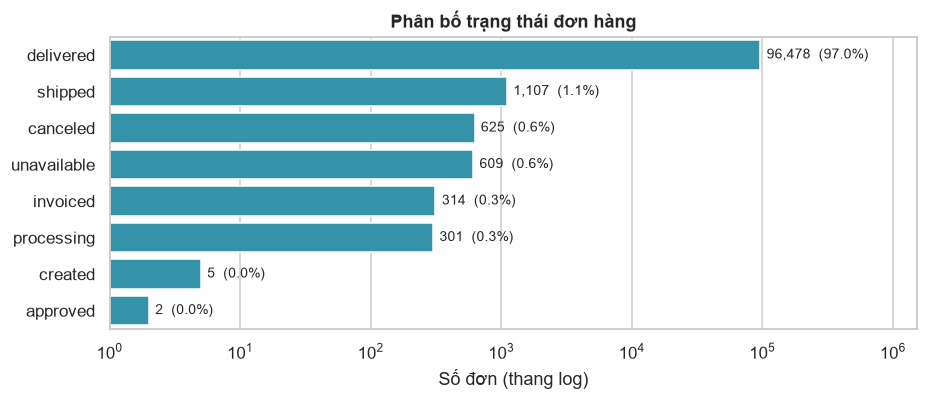

In [13]:
st = (df_order.order_status.value_counts().rename_axis("order_status").reset_index(name="so_don"))
st["ty_le_%"] = st.so_don / st.so_don.sum() * 100
display(st)
st.to_csv(f"{OUT_TAB}/05_trang_thai_don.csv", index=False, encoding="utf-8-sig")
KQ["tong_don"] = int(len(df_order))
KQ["don_delivered"] = int(len(dlv))
KQ["ty_le_delivered_pct"] = round(len(dlv) / len(df_order) * 100, 2)

fig, ax = plt.subplots(figsize=(8.6, 3.8))
sns.barplot(data=st, y="order_status", x="so_don", color="#219ebc", ax=ax)
ax.set_xscale("log"); ax.set_xlabel("Số đơn (thang log)"); ax.set_ylabel("")
ax.set_title("Phân bố trạng thái đơn hàng")
for i, r in st.iterrows():
    ax.text(r.so_don * 1.12, i, f"{r.so_don:,}  ({r['ty_le_%']:.1f}%)", va="center", fontsize=9)
ax.set_xlim(1, st.so_don.max() * 16)
plt.tight_layout(); luu_hinh("02_trang_thai_don"); plt.show()

**Nhận xét:**
Trong 99.441 đơn toàn sàn, có 96.478 đơn đạt trạng thái `delivered` (chiếm 97,02%). Các trạng thái còn lại chiếm tỷ lệ nhỏ: `shipped` 1,11%, `canceled` 0,63%, `unavailable` 0,61%, `invoiced` 0,32%, `processing` 0,30%, còn `created` và `approved` dưới 0,01%. Vì vậy việc lọc nhóm `delivered` để tính doanh thu thực là hợp lý.

Các tháng đầu (2016) và tháng cuối (09-10/2018) có rất ít đơn hoặc không đầy đủ:


purchase_month,2016-09-01,2016-10-01,2016-12-01
so_don,1.00,265.00,1.00
doanh_thu,134.97,"40,325.11",10.90


purchase_month,2018-06-01,2018-07-01,2018-08-01
so_don,"6,099.00","6,159.00","6,351.00"
doanh_thu,"856,077.86","867,953.46","838,576.64"


,so_don,doanh_thu,phi_ship,gia_tri_don_tb,tang_truong_mom_pct
purchase_month,,,,,
2017-01-01,750,"111,798.40","15,684.00",149.10,NaN
2017-02-01,1653,"234,223.40","37,015.90",141.70,109.50
2017-03-01,2546,"359,198.80","55,132.10",141.10,53.40
2017-04-01,2303,"340,669.70","50,142.70",147.90,-5.20
2017-05-01,3546,"489,338.20","77,513.20",138.00,43.60
2017-06-01,3135,"421,923.40","68,127.00",134.60,-13.80
2017-07-01,3872,"481,604.50","84,694.60",124.40,14.10
2017-08-01,4193,"554,699.70","91,132.70",132.30,15.20
2017-09-01,4150,"607,399.70","93,677.80",146.40,9.50



Tháng đỉnh: 11/2017 - 987,765 R$ (7,289 đơn); tăng so với tháng trước 52.4%
Doanh thu 8 tháng đầu 2018 so với cùng kỳ 2017: +141.1%  | số đơn: +139.9%


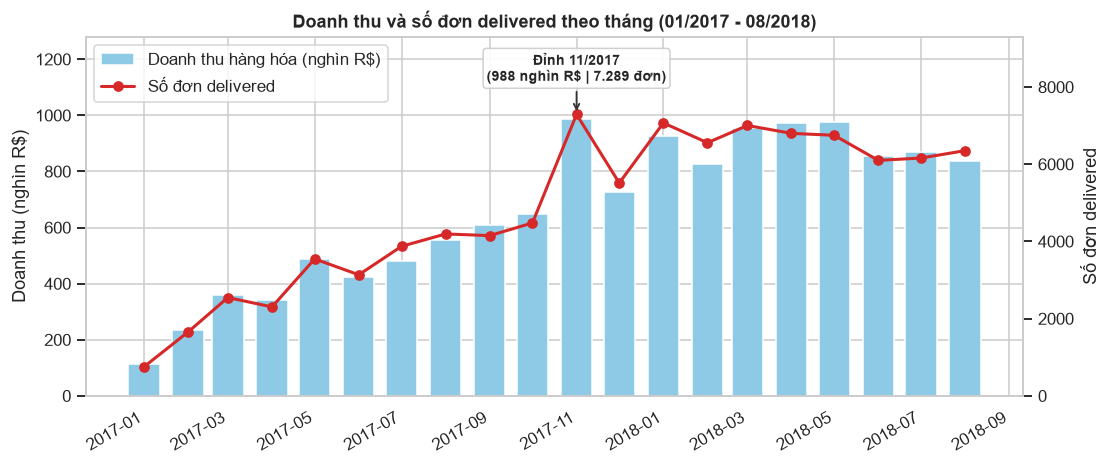

In [14]:
monthly = (dlv.groupby("purchase_month")
              .agg(so_don=("order_id", "nunique"),
                   doanh_thu=("item_value", "sum"),
                   phi_ship=("freight_value", "sum"),
                   gia_tri_don_tb=("item_value", "mean"))
              )
print("Các tháng đầu (2016) và tháng cuối (09-10/2018) có rất ít đơn hoặc không đầy đủ:")
display(monthly.head(3)[["so_don", "doanh_thu"]].T)
display(monthly.tail(3)[["so_don", "doanh_thu"]].T)

# cửa sổ phân tích: các tháng đầy đủ 01/2017 - 08/2018
mw = monthly.loc["2017-01-01":"2018-08-01"].copy()
mw["tang_truong_mom_pct"] = mw.doanh_thu.pct_change() * 100
mw.to_csv(f"{OUT_TAB}/06_doanh_thu_theo_thang.csv", encoding="utf-8-sig")
display(mw.round(1))

dinh = mw.doanh_thu.idxmax()
yoy = (mw.loc["2018-01-01":"2018-08-01", "doanh_thu"].sum() / mw.loc["2017-01-01":"2017-08-01", "doanh_thu"].sum() - 1) * 100
yoy_don = (mw.loc["2018-01-01":"2018-08-01", "so_don"].sum() / mw.loc["2017-01-01":"2017-08-01", "so_don"].sum() - 1) * 100
KQ.update({
    "thang_dinh": dinh.strftime("%m/%Y"), "dt_thang_dinh": round(float(mw.doanh_thu.max()), 0),
    "don_thang_dinh": int(mw.loc[dinh, "so_don"]),
    "mom_thang_dinh_pct": round(float(mw.loc[dinh, "tang_truong_mom_pct"]), 1),
    "yoy_dt_pct": round(float(yoy), 1), "yoy_don_pct": round(float(yoy_don), 1),
    "tong_dt_window": round(float(mw.doanh_thu.sum()), 0), "tong_don_window": int(mw.so_don.sum()),
    "aov_window": round(float(dlv.loc[dlv.purchase_month.between("2017-01-01", "2018-08-01"), "item_value"].mean()), 1),
    "dt_2017_01": round(float(mw.loc[pd.Timestamp("2017-01-01"), "doanh_thu"]), 0),
    "dt_2018_08": round(float(mw.loc[pd.Timestamp("2018-08-01"), "doanh_thu"]), 0),
})
print(f"\nTháng đỉnh: {dinh:%m/%Y} - {mw.doanh_thu.max():,.0f} R$ ({mw.loc[dinh,'so_don']:,} đơn); "
      f"tăng so với tháng trước {mw.loc[dinh,'tang_truong_mom_pct']:.1f}%")
print(f"Doanh thu 8 tháng đầu 2018 so với cùng kỳ 2017: {yoy:+.1f}%  | số đơn: {yoy_don:+.1f}%")

fig, ax1 = plt.subplots(figsize=(11, 4.8))
x = mw.index
ax1.bar(x, mw.doanh_thu / 1e3, width=22, color="#8ecae6", label="Doanh thu hàng hóa (nghìn R$)")
ax1.set_ylabel("Doanh thu (nghìn R$)"); ax1.set_ylim(0, 1280)
ax2 = ax1.twinx()
ax2.plot(x, mw.so_don, color="#d62828", marker="o", lw=2, label="Số đơn delivered")
ax2.set_ylabel("Số đơn delivered"); ax2.set_ylim(0, 9300); ax2.grid(False)
dinh_dt_k = mw.doanh_thu.max() / 1e3
dinh_don = int(mw.loc[dinh, "so_don"])
ax2.annotate(f"Đỉnh {dinh:%m/%Y}\n({dinh_dt_k:,.0f} nghìn R$ | {dinh_don:,} đơn)".replace(",", "."),
             (dinh, dinh_don),
             xytext=(0, 22), textcoords="offset points", ha="center",
             bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#cccccc", alpha=0.92),
             arrowprops=dict(arrowstyle="->", color="#333", lw=1.2), fontsize=9, fontweight="bold")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")
ax1.set_title("Doanh thu và số đơn delivered theo tháng (01/2017 - 08/2018)")
fig.autofmt_xdate(); luu_hinh("03_doanh_thu_theo_thang"); plt.show()

**Nhận xét doanh số theo tháng:**
- Các tháng cuối năm 2016 (09 - 12/2016) và tháng 09 - 10/2018 có rất ít đơn hoặc chưa đủ tháng, nên phần phân tích xu hướng tháng tập trung vào 20 tháng đầy đủ từ 01/2017 đến 08/2018 (96.211 đơn, tổng doanh thu hàng hóa 13,18 triệu R\$, AOV trung bình 137,0 R\$).
- Doanh thu tăng khá nhanh theo thời gian, từ 111.798 R\$ (750 đơn) tháng 01/2017 lên 838.577 R\$ (6.351 đơn) tháng 08/2018. Tính chung 8 tháng đầu năm 2018 so với cùng kỳ 2017, doanh thu tăng +141,1% và số đơn tăng +139,9%. Vì giá trị đơn trung bình khá ổn định quanh mức 125 - 150 R\$, tăng trưởng doanh thu chủ yếu đến từ việc tăng số lượng đơn hàng.
- Tháng 11/2017 đạt mức cao nhất với 987.765 R\$ và 7.289 đơn (tăng +52,4% so với tháng 10/2017), trùng dịp Black Friday; sang tháng 12/2017 giảm 26,5% về lại mức nền. Từ đầu năm 2018 đến 08/2018, doanh thu đi ngang quanh khoảng 830 - 980 nghìn R\$/tháng.

Thứ nhiều đơn nhất: Thứ 2 | ít nhất: Thứ 7
Khung giờ cao điểm: 16 h | tỷ lệ đơn trong 10h-22h: 81.5 % | cuối tuần: 23.0 %


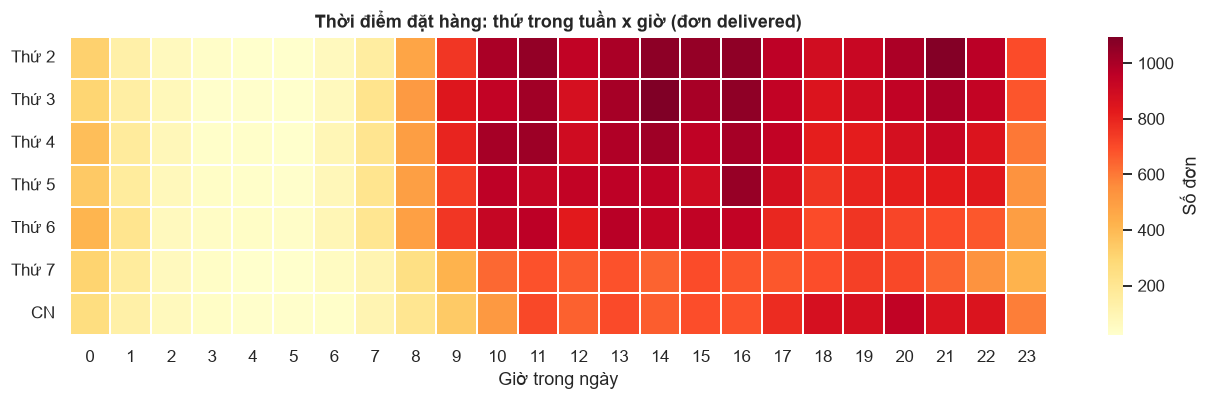

In [15]:
t = dlv.copy()
t["thu"] = t.order_purchase_timestamp.dt.dayofweek
t["gio"] = t.order_purchase_timestamp.dt.hour
heat = t.pivot_table(index="thu", columns="gio", values="order_id", aggfunc="count", fill_value=0)
heat.index = ["Thứ 2", "Thứ 3", "Thứ 4", "Thứ 5", "Thứ 6", "Thứ 7", "CN"]

theo_thu = t.groupby("thu").size()
theo_gio = t.groupby("gio").size()
KQ["thu_nhieu_nhat"] = ["Thứ 2", "Thứ 3", "Thứ 4", "Thứ 5", "Thứ 6", "Thứ 7", "CN"][int(theo_thu.idxmax())]
KQ["thu_it_nhat"] = ["Thứ 2", "Thứ 3", "Thứ 4", "Thứ 5", "Thứ 6", "Thứ 7", "CN"][int(theo_thu.idxmin())]
KQ["gio_cao_diem"] = int(theo_gio.idxmax())
KQ["ty_le_10_22h_pct"] = round(float(theo_gio.loc[10:22].sum() / theo_gio.sum() * 100), 1)
KQ["ty_le_cuoi_tuan_pct"] = round(float(theo_thu.loc[[5, 6]].sum() / theo_thu.sum() * 100), 1)
print("Thứ nhiều đơn nhất:", KQ["thu_nhieu_nhat"], "| ít nhất:", KQ["thu_it_nhat"])
print("Khung giờ cao điểm:", KQ["gio_cao_diem"], "h | tỷ lệ đơn trong 10h-22h:", KQ["ty_le_10_22h_pct"], "% | cuối tuần:", KQ["ty_le_cuoi_tuan_pct"], "%")

plt.figure(figsize=(12, 3.8))
sns.heatmap(heat, cmap="YlOrRd", cbar_kws={"label": "Số đơn"}, linewidths=0.3, linecolor="white")
plt.yticks(rotation=0); plt.xticks(rotation=0)
plt.xlabel("Giờ trong ngày"); plt.ylabel(""); plt.title("Thời điểm đặt hàng: thứ trong tuần x giờ (đơn delivered)")
plt.tight_layout(); luu_hinh("04_thu_gio_dat_hang"); plt.show()

**Nhận xét theo thứ và khung giờ:**
Khách đặt hàng nhiều nhất vào Thứ 2 (và tập trung từ Thứ 2 đến Thứ 5), ít nhất vào Thứ 7; tổng hai ngày cuối tuần chỉ chiếm 23,0% số đơn. Xét theo giờ trong ngày, 81,5% số đơn rơi vào khung 10h - 22h, cao điểm nhất lúc 16h và thấp nhất vào rạng sáng (2h - 6h).

## 7. Phân tích doanh số theo nhóm ngành hàng
Dùng bảng mức sản phẩm `di` (110.197 dòng của các đơn `delivered`), chuyển 74 tên ngành hàng sang tiếng Việt để tính doanh thu, số đơn, giá bán trung bình/trung vị, kiểm tra đường cong Pareto 80/20 và theo dõi biến động theo tháng của 5 ngành dẫn đầu.

,so_don,so_san_pham,doanh_thu,gia_tb,gia_trung_vi,ty_trong_pct,luy_ke_pct
category_vi,,,,,,,
Sức khỏe & làm đẹp,8647,9465,"1,233,131.70",130.30,79.90,9.30,9.30
Đồng hồ & quà tặng,5495,5859,"1,166,177.00",199.00,129.00,8.80,18.10
Giường - bàn - phòng tắm,9272,10953,"1,023,434.80",93.40,79.00,7.70,25.90
Thể thao & giải trí,7530,8431,"954,852.60",113.30,77.90,7.20,33.10
Phụ kiện máy tính,6530,7644,"888,724.60",116.30,82.00,6.70,39.80
Nội thất & trang trí,6307,8160,"711,927.70",87.20,65.50,5.40,45.20
Đồ gia dụng,5743,6795,"615,628.70",90.60,59.70,4.70,49.90
Đồ độc đáo,3559,3718,"610,204.10",164.10,129.90,4.60,54.50
Ô tô,3810,4140,"578,966.60",139.80,84.90,4.40,58.90


18/74 ngành hàng tạo ra 80% doanh thu | top 10 chiếm 62.4%


,so_san_pham,gia_tb,gia_trung_vi
category_vi,,,
Nhạc cụ,651,283.10,94.90
Điện gia dụng nhỏ,658,277.70,98.40
Đồng hồ & quà tặng,5859,199.00,129.00
Đồ độc đáo,3718,164.10,129.90
Nội thất văn phòng,1668,160.80,144.90


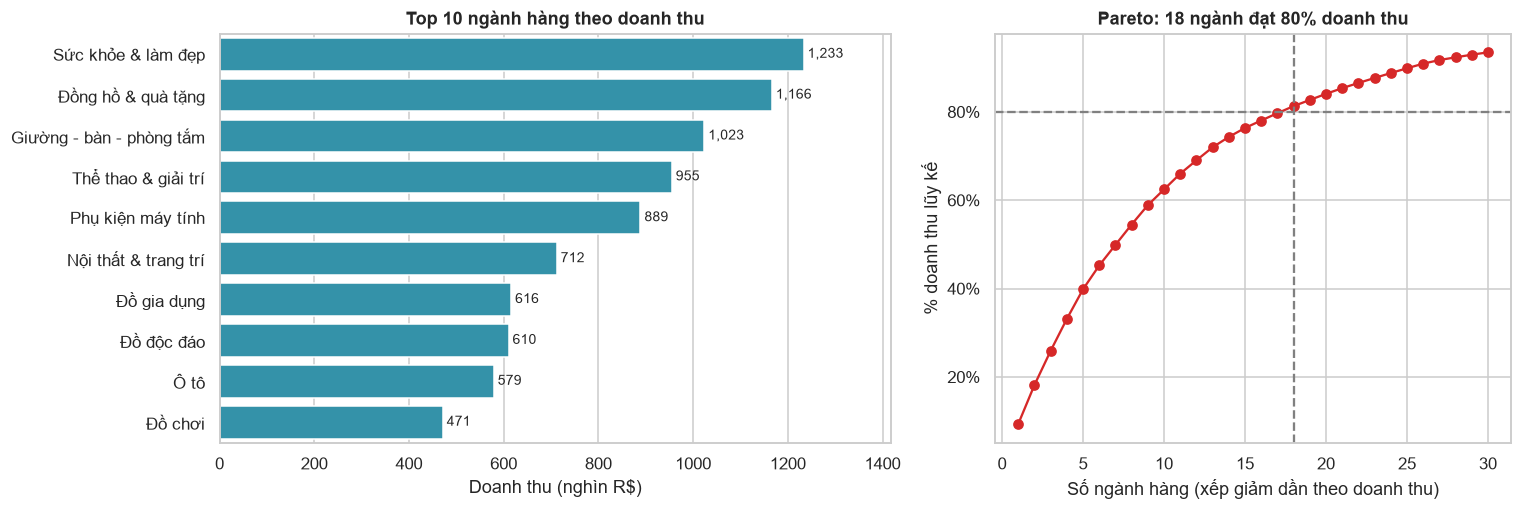

In [16]:
vi = {
    "bed_bath_table": "Giường - bàn - phòng tắm", "health_beauty": "Sức khỏe & làm đẹp", "sports_leisure": "Thể thao & giải trí",
    "computers_accessories": "Phụ kiện máy tính", "furniture_decor": "Nội thất & trang trí", "watches_gifts": "Đồng hồ & quà tặng",
    "housewares": "Đồ gia dụng", "telephony": "Điện thoại", "garden_tools": "Dụng cụ làm vườn", "auto": "Ô tô",
    "toys": "Đồ chơi", "cool_stuff": "Đồ độc đáo", "perfumery": "Nước hoa", "baby": "Mẹ & bé", "electronics": "Điện tử",
    "stationery": "Văn phòng phẩm", "fashion_bags_accessories": "Túi & phụ kiện thời trang", "pet_shop": "Thú cưng",
    "office_furniture": "Nội thất văn phòng", "luggage_accessories": "Vali & phụ kiện", "small_appliances": "Điện gia dụng nhỏ",
    "consoles_games": "Máy chơi game", "musical_instruments": "Nhạc cụ", "home_appliances": "Thiết bị gia dụng",
    "construction_tools_construction": "Vật liệu xây dựng", "food": "Thực phẩm", "furniture_living_room": "Nội thất phòng khách",
    "home_confort": "Đồ tiện nghi gia đình", "kitchen_dining_laundry_garden_furniture": "Bếp - ăn - giặt - vườn",
    "books_general_interest": "Sách phổ thông", "unknown": "Không xác định", "air_conditioning": "Điều hòa",
    "market_place": "Bách hóa tổng hợp", "fixed_telephony": "Điện thoại bàn", "home_construction": "Xây dựng nhà",
    "drinks": "Đồ uống", "signaling_and_security": "Thiết bị an ninh", "industry_commerce_and_business": "Công nghiệp & kinh doanh",
    "costruction_tools_garden": "Dụng cụ xây dựng - vườn", "agro_industry_and_commerce": "Nông nghiệp", "art": "Nghệ thuật",
    "audio": "Âm thanh", "cine_photo": "Phim - ảnh", "computers": "Máy tính (PC)", "home_appliances_2": "Thiết bị gia dụng lớn",
    "small_appliances_home_oven_and_coffee": "Lò nướng & máy pha cà phê", "construction_tools_lights": "Thiết bị chiếu sáng",
    "construction_tools_safety": "Bảo hộ xây dựng", "fashion_shoes": "Giày dép", "furniture_bedroom": "Nội thất phòng ngủ",
    "books_technical": "Sách chuyên ngành", "costruction_tools_tools": "Dụng cụ xây dựng", "food_drink": "Thực phẩm & đồ uống",
    "fashion_male_clothing": "Thời trang nam", "fashion_underwear_beach": "Đồ lót & đồ đi biển",
    "christmas_supplies": "Đồ trang trí Giáng sinh", "tablets_printing_image": "Máy tính bảng & in ấn", "music": "Âm nhạc",
    "dvds_blu_ray": "Đĩa DVD & Blu-ray", "party_supplies": "Đồ trang trí tiệc", "books_imported": "Sách ngoại văn",
    "furniture_mattress_and_upholstery": "Nệm & bọc nội thất", "portable_kitchen_food_preparers": "Thiết bị chế biến thực phẩm",
    "fashio_female_clothing": "Thời trang nữ", "fashion_sport": "Đồ thể thao", "la_cuisine": "Đồ bếp cao cấp",
    "arts_and_craftmanship": "Thủ công mỹ nghệ", "diapers_and_hygiene": "Tã bỉm & vệ sinh", "pc_gamer": "PC Gaming",
    "flowers": "Hoa tươi", "home_comfort_2": "Đồ tiện nghi (nhóm 2)", "cds_dvds_musicals": "Đĩa nhạc CD/DVD",
    "fashion_childrens_clothes": "Thời trang trẻ em", "security_and_services": "Dịch vụ bảo vệ",
}
di["category_vi"] = di.category_en.map(vi).fillna(di.category_en)

cat = (di.groupby("category_vi")
         .agg(so_don=("order_id", "nunique"), so_san_pham=("order_item_id", "size"),
              doanh_thu=("price", "sum"), gia_tb=("price", "mean"), gia_trung_vi=("price", "median"))
         .sort_values("doanh_thu", ascending=False))
cat["ty_trong_pct"] = cat.doanh_thu / cat.doanh_thu.sum() * 100
cat["luy_ke_pct"] = cat.ty_trong_pct.cumsum()
cat.to_csv(f"{OUT_TAB}/07_nganh_hang.csv", encoding="utf-8-sig")
top10 = cat.head(10)
display(top10.round(1))

n80 = int((cat.luy_ke_pct < 80).sum() + 1)
KQ.update({
    "so_nganh": int(len(cat)), "n_nganh_80pct": n80,
    "top10": [[k, round(float(v.doanh_thu), 0), round(float(v.ty_trong_pct), 1), int(v.so_don), round(float(v.gia_tb), 1)] for k, v in top10.iterrows()],
    "top10_ty_trong_pct": round(float(top10.ty_trong_pct.sum()), 1),
    "top1_ten": top10.index[0], "top1_pct": round(float(top10.ty_trong_pct.iloc[0]), 1),
})
print(f"{n80}/{len(cat)} ngành hàng tạo ra 80% doanh thu | top 10 chiếm {top10.ty_trong_pct.sum():.1f}%")

# ngành có giá trung bình cao nhất (loại ngành quá ít đơn)
cao = cat[cat.so_san_pham >= 500].sort_values("gia_tb", ascending=False).head(5)
KQ["nganh_gia_cao"] = [[k, round(float(v.gia_tb), 1)] for k, v in cao.iterrows()]
display(cao[["so_san_pham", "gia_tb", "gia_trung_vi"]].round(1))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
sns.barplot(x=top10.doanh_thu / 1e3, y=top10.index, color="#219ebc", ax=ax[0])
ax[0].set_xlabel("Doanh thu (nghìn R$)"); ax[0].set_ylabel(""); ax[0].set_title("Top 10 ngành hàng theo doanh thu")
for i, v in enumerate(top10.doanh_thu / 1e3):
    ax[0].text(v, i, f" {v:,.0f}", va="center", fontsize=9)
ax[0].set_xlim(0, top10.doanh_thu.max() / 1e3 * 1.15)

p20 = cat.head(30)
ax[1].plot(range(1, len(p20) + 1), p20.luy_ke_pct, marker="o", color="#d62828")
ax[1].axhline(80, ls="--", color="gray"); ax[1].axvline(n80, ls="--", color="gray")
ax[1].set_xlabel("Số ngành hàng (xếp giảm dần theo doanh thu)"); ax[1].set_ylabel("% doanh thu lũy kế")
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter()); ax[1].set_title(f"Pareto: {n80} ngành đạt 80% doanh thu")
plt.tight_layout(); luu_hinh("05_nganh_hang_top10_pareto"); plt.show()

**Nhận xét cơ cấu ngành hàng:**
- Trong 74 nhóm ngành hàng, 10 nhóm đứng đầu chiếm 62,4% doanh thu và cần 18 nhóm (24,3% tổng số ngành) để đạt mốc 80% doanh thu theo quy luật Pareto. Doanh thu không dồn quá nặng vào một ngành duy nhất: đứng đầu là Sức khỏe & làm đẹp (9,3%, khoảng 1,23 triệu R\$), kế tiếp là Đồng hồ & quà tặng (8,8%, 1,17 triệu R\$) và Giường - bàn - phòng tắm (7,7%, 1,02 triệu R\$).
- Ngành Giường - bàn - phòng tắm có nhiều đơn hàng nhất (9.272 đơn) nhưng đơn giá trung bình thấp (93,4 R\$) nên đứng thứ 3 về doanh thu. Ngược lại, Đồng hồ & quà tặng chỉ có 5.495 đơn nhưng đơn giá trung bình 199,0 R\$ nên xếp thứ 2. Nếu chỉ xét các ngành bán từ 500 sản phẩm trở lên, nhóm có giá trung bình cao nhất là Nhạc cụ (283,1 R\$) và Điện gia dụng nhỏ (277,7 R\$).

purchase_month,2017-01-01,2017-02-01,2017-03-01,2017-04-01,2017-05-01,2017-06-01,2017-07-01,2017-08-01,2017-09-01,2017-10-01,2017-11-01,2017-12-01,2018-01-01,2018-02-01,2018-03-01,2018-04-01,2018-05-01,2018-06-01,2018-07-01,2018-08-01
category_vi,,,,,,,,,,,,,,,,,,,,
Sức khỏe & làm đẹp,12.00,22.00,26.00,22.00,46.00,32.00,34.00,49.00,51.00,41.00,78.00,61.00,71.00,85.00,84.00,91.00,95.00,107.00,104.00,119.00
Đồng hồ & quà tặng,8.00,11.00,25.00,23.00,37.00,27.00,34.00,36.00,45.00,65.00,95.00,70.00,74.00,61.00,96.00,89.00,119.00,85.00,95.00,70.00
Giường - bàn - phòng tắm,4.00,16.00,25.00,24.00,33.00,34.00,63.00,57.00,52.00,46.00,88.00,50.00,75.00,60.00,68.00,71.00,71.00,71.00,54.00,61.00
Thể thao & giải trí,9.00,16.00,25.00,23.00,34.00,32.00,37.00,41.00,49.00,49.00,63.00,59.00,86.00,75.00,82.00,66.00,59.00,45.00,54.00,51.00
Phụ kiện máy tính,4.00,11.00,28.00,18.00,45.00,36.00,38.00,34.00,28.00,42.00,70.00,37.00,81.00,100.00,85.00,57.00,51.00,42.00,41.00,40.00


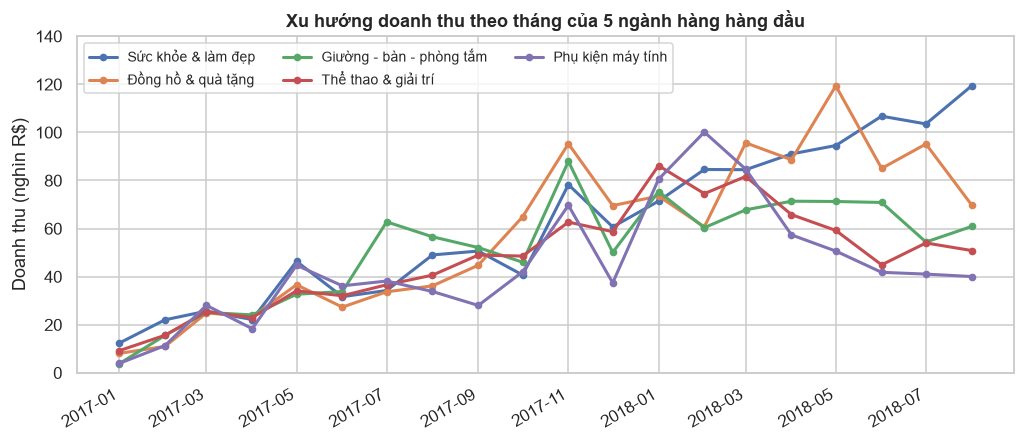

{'Sức khỏe & làm đẹp': '08/2018', 'Đồng hồ & quà tặng': '05/2018', 'Giường - bàn - phòng tắm': '11/2017', 'Thể thao & giải trí': '01/2018', 'Phụ kiện máy tính': '02/2018'}


In [17]:
top5 = top10.index[:5]
pv = (di[di.category_vi.isin(top5)].pivot_table(index="purchase_month", columns="category_vi", values="price", aggfunc="sum")
        .loc["2017-01-01":"2018-08-01", top5] / 1e3)
pv.round(1).to_csv(f"{OUT_TAB}/08_top5_nganh_theo_thang.csv", encoding="utf-8-sig")
display(pv.round(0).T)

fig, ax = plt.subplots(figsize=(11, 4.5))
for c in top5:
    ax.plot(pv.index, pv[c], marker="o", ms=4, lw=2, label=c)
ax.set_ylim(0, 140); ax.set_ylabel("Doanh thu (nghìn R$)")
ax.set_title("Xu hướng doanh thu theo tháng của 5 ngành hàng hàng đầu")
ax.legend(ncol=3, fontsize=9, loc="upper left"); fig.autofmt_xdate(); luu_hinh("06_top5_nganh_theo_thang"); plt.show()

# tháng đỉnh của từng ngành
KQ["dinh_nganh"] = {c: pv[c].idxmax().strftime("%m/%Y") for c in top5}
print(KQ["dinh_nganh"])

**Nhận xét xu hướng Top 5 ngành theo tháng:**
Cả 5 ngành dẫn đầu đều tăng rõ trong năm 2017 và cùng tăng mạnh vào tháng 11/2017 (đặc biệt Giường - bàn - phòng tắm đạt đỉnh ngay trong tháng này). Sang năm 2018, các nhóm đi theo hướng khác nhau: Sức khỏe & làm đẹp tiếp tục tăng và đạt đỉnh 119 nghìn R\$ vào 08/2018; Đồng hồ & quà tặng đạt đỉnh vào 05/2018 (trùng dịp Ngày của Mẹ tại Brazil); còn Thể thao & giải trí (01/2018) và Phụ kiện máy tính (02/2018) đạt đỉnh đầu năm rồi giảm dần.

## 8. Phân tích doanh số theo phương thức thanh toán
Thống kê số đơn, tổng tiền (`payment_value`) và giá trị đơn trung bình theo phương thức thanh toán chính (xác định bằng phương thức có tổng tiền lớn nhất trong mỗi đơn), sau đó phân tích hành vi trả góp thẻ tín dụng và cơ cấu phương thức theo tháng.

,so_don,tong_tien,tien_tb,tien_trung_vi,ty_le_don_pct,ty_le_tien_pct
main_payment_type,,,,,,
credit_card,72785,"12,095,049.20",166.20,109.40,75.40,78.40
boleto,19191,"2,769,932.60",144.30,93.80,19.90,18.00
voucher,3017,"349,108.80",115.70,82.00,3.10,2.30
debit_card,1484,"208,371.10",140.40,89.60,1.50,1.40


Đơn dùng từ 2 loại phương thức thanh toán trở lên: 2.26%


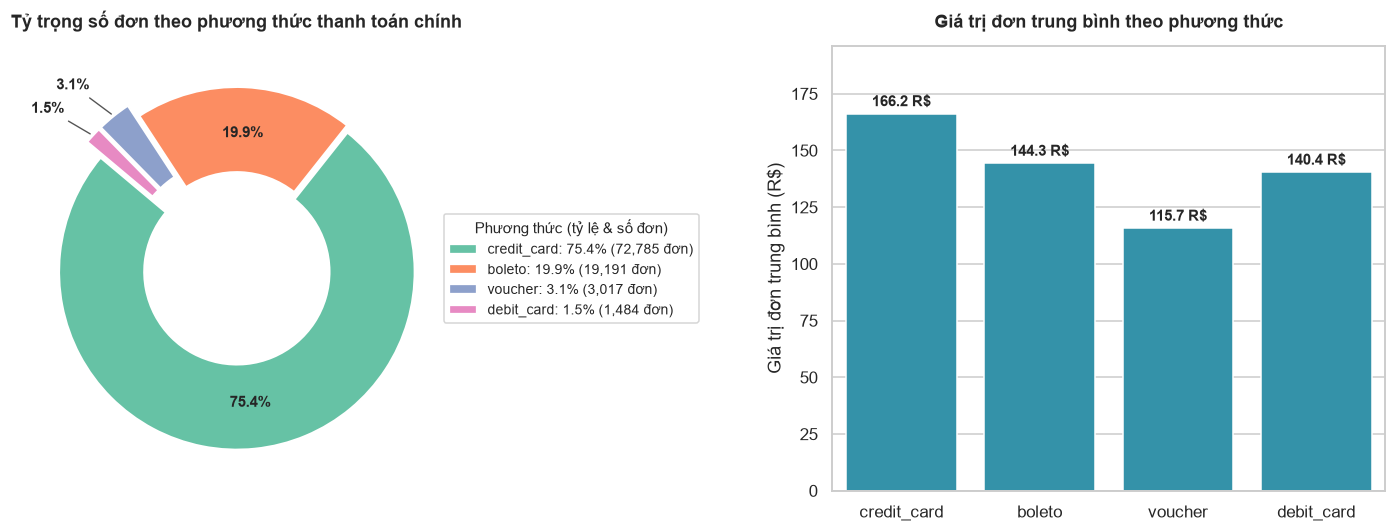

In [18]:
pt = (dlv.dropna(subset=["main_payment_type"])
         .groupby("main_payment_type")
         .agg(so_don=("order_id", "count"), tong_tien=("payment_value", "sum"),
              tien_tb=("payment_value", "mean"), tien_trung_vi=("payment_value", "median"))
         .sort_values("so_don", ascending=False))
pt["ty_le_don_pct"] = pt.so_don / pt.so_don.sum() * 100
pt["ty_le_tien_pct"] = pt.tong_tien / pt.tong_tien.sum() * 100
pt.to_csv(f"{OUT_TAB}/09_phuong_thuc_thanh_toan.csv", encoding="utf-8-sig")
display(pt.round(1))

multi = float((dlv.n_payment_types > 1).mean() * 100)
KQ.update({
    "pt": [[k, int(v.so_don), round(float(v.ty_le_don_pct), 1), round(float(v.ty_le_tien_pct), 1),
            round(float(v.tien_tb), 1), round(float(v.tien_trung_vi), 1)] for k, v in pt.iterrows()],
    "don_nhieu_pt_pct": round(multi, 2),
})
print(f"Đơn dùng từ 2 loại phương thức thanh toán trở lên: {multi:.2f}%")

fig, ax = plt.subplots(1, 2, figsize=(14.2, 5.0), gridspec_kw={"width_ratios": [1.35, 1]})
colors_pt = sns.color_palette("Set2", len(pt))
explode_vals = [0.02 if pct >= 10 else 0.10 for pct in pt.ty_le_don_pct]

wedges, _ = ax[0].pie(
    pt.so_don, labels=None, startangle=140, colors=colors_pt,
    explode=explode_vals,
    wedgeprops=dict(width=0.48, edgecolor="white", linewidth=1.5),
)[:2]

for w, pct in zip(wedges, pt.ty_le_don_pct):
    ang = (w.theta2 + w.theta1) / 2
    rad = np.deg2rad(ang)
    cx, cy = w.center
    if pct >= 10:
        ax[0].text(cx + np.cos(rad) * 0.74, cy + np.sin(rad) * 0.74, f"{pct:.1f}%",
                   fontsize=10, fontweight="bold", ha="center", va="center")
    else:
        x_neo, y_neo = cx + np.cos(rad) * 1.0, cy + np.sin(rad) * 1.0
        x_txt, y_txt = cx + np.cos(rad) * 1.22, cy + np.sin(rad) * 1.22
        ax[0].annotate(
            f"{pct:.1f}%", xy=(x_neo, y_neo), xytext=(x_txt, y_txt),
            fontsize=10, fontweight="bold", ha="left" if x_txt >= 0 else "right", va="center",
            arrowprops=dict(arrowstyle="-", color="#555", lw=0.9),
        )

nhan_legend = [f"{k}: {r.ty_le_don_pct:.1f}% ({int(r.so_don):,} đơn)" for k, r in pt.iterrows()]
ax[0].legend(wedges, nhan_legend, title="Phương thức (tỷ lệ & số đơn)", loc="center left",
             bbox_to_anchor=(0.95, 0.5), frameon=True, fontsize=9, title_fontsize=9.5)
ax[0].set_title("Tỷ trọng số đơn theo phương thức thanh toán chính", pad=12)

sns.barplot(x=pt.index, y=pt.tien_tb, color="#219ebc", ax=ax[1], order=pt.index)
for i, v in enumerate(pt.tien_tb):
    ax[1].text(i, v + 2, f"{v:,.1f} R$", ha="center", va="bottom", fontsize=9.5, fontweight="bold")
ax[1].set_ylim(0, pt.tien_tb.max() * 1.18)
ax[1].set_ylabel("Giá trị đơn trung bình (R$)"); ax[1].set_xlabel("")
ax[1].set_title("Giá trị đơn trung bình theo phương thức", pad=12)
plt.tight_layout(); luu_hinh("07_phuong_thuc_thanh_toan"); plt.show()

**Nhận xét về phương thức thanh toán:**
- Thẻ tín dụng (`credit_card`) chiếm tỷ trọng lớn nhất với 75,4% số đơn (72.785 đơn) và 78,4% tổng giá trị thanh toán (12,10 triệu R\$), đồng thời có giá trị đơn trung bình cao nhất (166,2 R\$, trung vị 109,4 R\$).
- Đứng thứ 2 là `boleto` (phiếu thanh toán tiền mặt phổ biến tại Brazil) với 19,9% số đơn (19.191 đơn, 18,0% tổng tiền), giá trị đơn trung bình 144,3 R\$.
- Hai hình thức còn lại là `voucher` (3,1% số đơn, 2,3% tiền, đơn trung bình thấp nhất 115,7 R\$) và `debit_card` (1,5% số đơn, 1,4% tiền) chiếm tỷ lệ rất nhỏ. Do chỉ có 2,26% đơn hàng dùng từ 2 phương thức trở lên, cách xác định phương thức chính theo tổng tiền lớn nhất phản ánh sát thực tế.

,so_don,tien_tb,trung_vi,ty_le_pct
nhom_tra_gop,,,,
1 kỳ,23330,100.50,71.40,32.10
2-3 kỳ,22011,134.90,111.40,30.20
4-6 kỳ,15693,181.70,128.00,21.60
7-10 kỳ,11422,333.50,206.10,15.70
>10 kỳ,329,361.50,218.80,0.50


Đơn thẻ tín dụng trả góp (>1 kỳ): 67.9% | số kỳ trung bình: 3.55


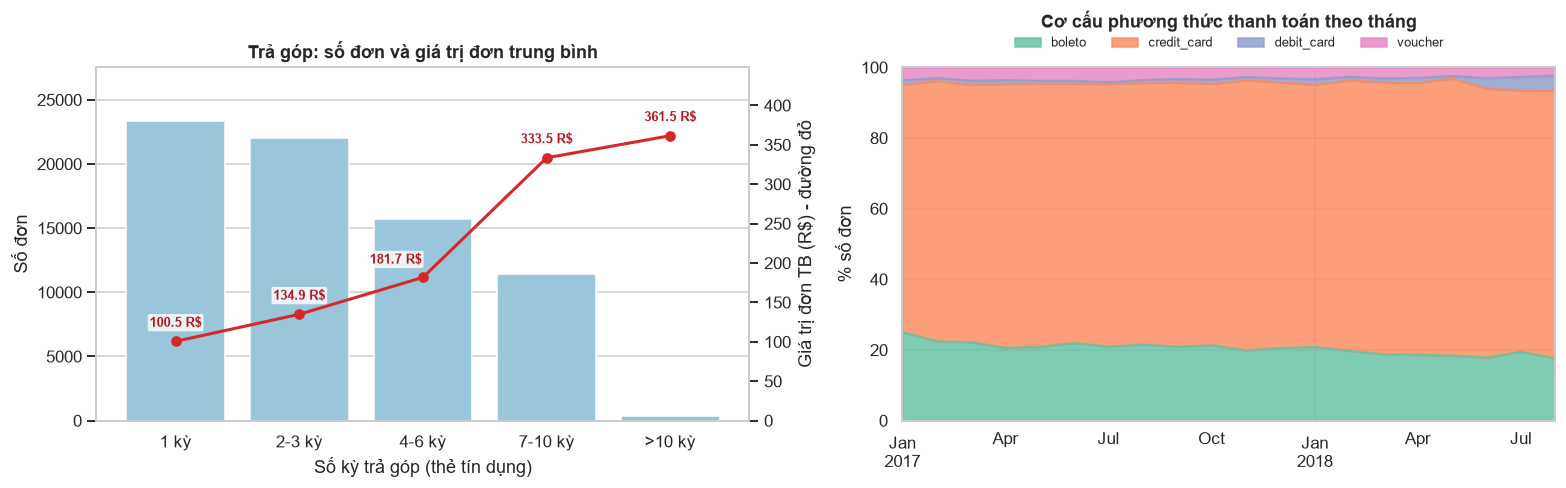

Boleto tháng thấp nhất / cao nhất: 17.6% / 25.1%


In [19]:
cc = dlv[dlv.main_payment_type == "credit_card"].copy()
cc["nhom_tra_gop"] = pd.cut(cc.max_installments, [0, 1, 3, 6, 10, 24],
                            labels=["1 kỳ", "2-3 kỳ", "4-6 kỳ", "7-10 kỳ", ">10 kỳ"])
ins = (cc.groupby("nhom_tra_gop", observed=True)
         .agg(so_don=("order_id", "count"), tien_tb=("payment_value", "mean"), trung_vi=("payment_value", "median")))
ins["ty_le_pct"] = ins.so_don / ins.so_don.sum() * 100
ins.to_csv(f"{OUT_TAB}/10_tra_gop_the_tin_dung.csv", encoding="utf-8-sig")
display(ins.round(1))

tg_tren1 = float((cc.max_installments > 1).mean() * 100)
KQ["ins"] = [[str(k), int(v.so_don), round(float(v.ty_le_pct), 1), round(float(v.tien_tb), 1)] for k, v in ins.iterrows()]
KQ["credit_tra_gop_pct"] = round(tg_tren1, 1)
KQ["credit_ky_tb"] = round(float(cc.max_installments.mean()), 2)
print(f"Đơn thẻ tín dụng trả góp (>1 kỳ): {tg_tren1:.1f}% | số kỳ trung bình: {cc.max_installments.mean():.2f}")

# xu hướng cơ cấu thanh toán theo tháng (pivot -> chia tỷ lệ)
share = (dlv.pivot_table(index="purchase_month", columns="main_payment_type", values="order_id", aggfunc="count", fill_value=0)
            .loc["2017-01-01":"2018-08-01"])
share = share.div(share.sum(axis=1), axis=0) * 100
share.round(1).to_csv(f"{OUT_TAB}/11_co_cau_thanh_toan_theo_thang.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(1, 2, figsize=(14.4, 4.6))
sns.barplot(data=ins.reset_index(), x="nhom_tra_gop", y="so_don", color="#8ecae6", ax=ax[0])
ax[0].set_ylim(0, ins.so_don.max() * 1.18)
ax0 = ax[0].twinx(); ax0.plot(range(len(ins)), ins.tien_tb, color="#d62828", marker="o", lw=2); ax0.grid(False)
ax0.set_ylim(0, ins.tien_tb.max() * 1.24)
for i, v in enumerate(ins.tien_tb):
    dx = -0.22 if i == 2 else 0.0
    dy = 15 if i != 2 else 14
    ax0.text(i + dx, v + dy, f"{v:.1f} R$", ha="center", va="bottom", fontsize=8.5, fontweight="bold",
             color="#b5171e", bbox=dict(boxstyle="round,pad=0.14", fc="white", ec="none", alpha=0.82))
ax0.set_ylabel("Giá trị đơn TB (R$) - đường đỏ")
ax[0].set_xlabel("Số kỳ trả góp (thẻ tín dụng)"); ax[0].set_ylabel("Số đơn"); ax[0].set_title("Trả góp: số đơn và giá trị đơn trung bình")

share.plot.area(ax=ax[1], alpha=.85, color=sns.color_palette("Set2"))
ax[1].set_ylim(0, 100); ax[1].set_ylabel("% số đơn"); ax[1].set_xlabel("")
ax[1].set_title("Cơ cấu phương thức thanh toán theo tháng", pad=26)
ax[1].legend(ncol=4, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, 1.12), frameon=False)
plt.tight_layout(); luu_hinh("08_tra_gop_va_co_cau_theo_thang"); plt.show()
print("Boleto tháng thấp nhất / cao nhất:", f"{share.boleto.min():.1f}% / {share.boleto.max():.1f}%")
KQ["boleto_min"], KQ["boleto_max"] = round(float(share.boleto.min()), 1), round(float(share.boleto.max()), 1)

**Nhận xét về trả góp và xu hướng theo tháng:**
- Có 67,9% số đơn thanh toán bằng thẻ tín dụng được chia trả góp từ 2 kỳ trở lên, trung bình 3,55 kỳ/đơn.
- Số kỳ trả góp tăng rõ theo giá trị đơn hàng: nhóm trả 1 kỳ (32,1% số đơn) có giá trị trung bình 100,5 R\$; nhóm 2 - 3 kỳ là 134,9 R\$; nhóm 4 - 6 kỳ là 181,7 R\$; nhóm 7 - 10 kỳ tăng lên 333,5 R\$ (gấp hơn 3 lần nhóm 1 kỳ); nhóm >10 kỳ đạt 361,5 R\$ nhưng số lượng đơn rất ít (0,5%).
- Theo thời gian, cơ cấu các phương thức khá ổn định; tỷ trọng `boleto` giảm nhẹ từ mức cao nhất 25,1% đầu năm 2017 xuống thấp nhất 17,6% vào giữa năm 2018.

## 9. Phân tích vận chuyển, thời gian giao hàng, giao trễ và đánh giá
Phân tích trên 96.470 đơn `delivered` có ngày giao hợp lệ (`valid_delivery == True`) theo 6 nội dung:
1. Thời gian giao hàng thực tế so với ngày hẹn và thời gian trung bình của 3 chặng vận hành.
2. Thời gian giao, tỷ lệ trễ và phí vận chuyển theo 5 vùng địa lý và 21 bang (có >= 300 đơn).
3. Doanh số, số đơn, phí vận chuyển và điểm đánh giá theo 5 nhóm thời gian giao hàng.
4. Diễn biến tỷ lệ giao trễ theo tháng.
5. Mối liên hệ giữa mức độ giao trễ và điểm đánh giá (`review_score`).
6. Phân bố doanh thu và tỷ lệ phí vận chuyển theo Top 10 bang.

,count,mean,std,min,50%,90%,95%,max
approve_hours,"96,456.00",10.28,20.54,0.00,0.34,34.59,48.26,741.44
carrier_days,"95,105.00",2.85,3.49,0.00,1.85,6.02,8.15,125.76
transit_days,"96,446.00",9.33,8.76,0.00,7.10,18.90,24.21,205.19
delivery_days,"96,470.00",12.56,9.55,0.53,10.22,23.10,29.27,209.63
estimated_days,"96,470.00",23.74,8.76,2.01,23.23,34.29,38.42,155.14
delay_days,"96,470.00",-11.88,10.18,-147.00,-12.00,-2.00,3.00,188.00


Giao hàng TB 12.6 ngày (trung vị 10.2, P90 23.1); hẹn TB 23.7 ngày; tỷ lệ giao trễ 6.77%

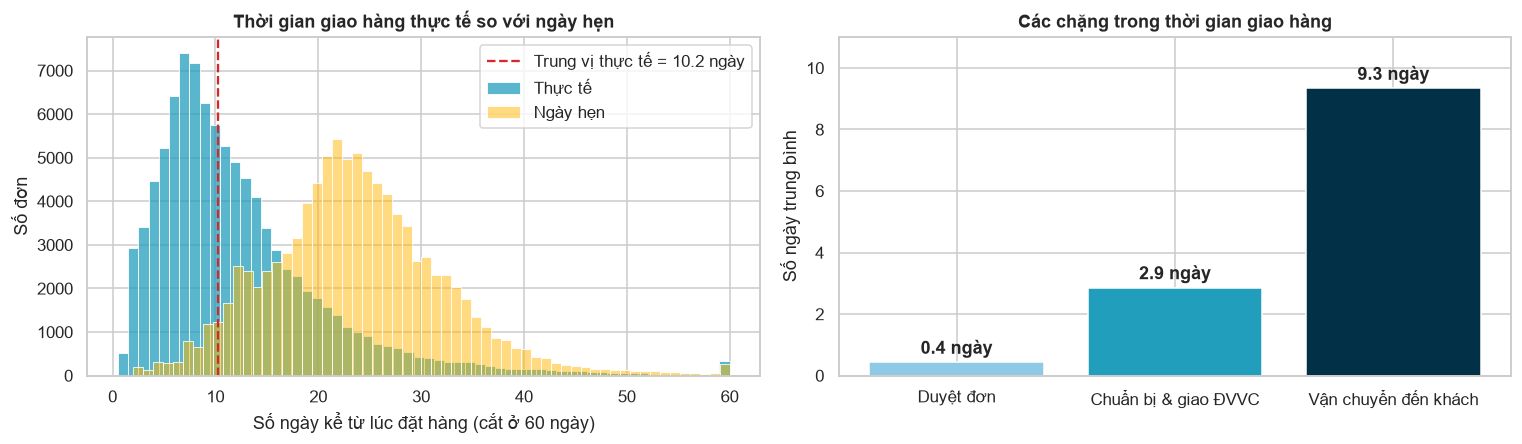

In [20]:
dd = dlv[dlv.valid_delivery].copy()
mo_ta = dd[["approve_hours", "carrier_days", "transit_days", "delivery_days", "estimated_days", "delay_days"]].describe(
    percentiles=[.5, .9, .95]).T.round(2)
display(mo_ta)
mo_ta.to_csv(f"{OUT_TAB}/12_mo_ta_thoi_gian_giao_hang.csv", encoding="utf-8-sig")

late = dd.is_late.mean() * 100
KQ.update({
    "giao_tb": round(float(dd.delivery_days.mean()), 1), "giao_trung_vi": round(float(dd.delivery_days.median()), 1),
    "giao_p90": round(float(dd.delivery_days.quantile(.9)), 1), "giao_max": round(float(dd.delivery_days.max()), 0),
    "du_kien_tb": round(float(dd.estimated_days.mean()), 1), "ty_le_tre_pct": round(float(late), 2),
    "tre_tb_ngay": round(float(dd.loc[dd.is_late, "delay_days"].mean()), 1),
    "som_hon_tb": round(float(-dd.delay_days.mean()), 1),
    "duyet_tb_gio": round(float(dd.approve_hours.mean()), 1), "carrier_tb": round(float(dd.carrier_days.mean()), 1),
    "transit_tb": round(float(dd.transit_days.mean()), 1), "n_giao_hop_le": int(len(dd)),
    "ngoai_le_giao_n": int(n_out), "ngoai_le_giao_pct": round(float(n_out / len(dd) * 100), 2),
})
print(f"Giao hàng TB {dd.delivery_days.mean():.1f} ngày (trung vị {dd.delivery_days.median():.1f}, P90 {dd.delivery_days.quantile(.9):.1f}); "
      f"hẹn TB {dd.estimated_days.mean():.1f} ngày; tỷ lệ giao trễ {late:.2f}%")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
sns.histplot(dd.delivery_days.clip(upper=60), bins=60, color="#219ebc", ax=ax[0], label="Thực tế")
sns.histplot(dd.estimated_days.clip(upper=60), bins=60, color="#ffb703", alpha=.5, ax=ax[0], label="Ngày hẹn")
ax[0].axvline(dd.delivery_days.median(), color="#d62828", ls="--", label=f"Trung vị thực tế = {dd.delivery_days.median():.1f} ngày")
ax[0].set_xlabel("Số ngày kể từ lúc đặt hàng (cắt ở 60 ngày)"); ax[0].set_ylabel("Số đơn")
ax[0].set_title("Thời gian giao hàng thực tế so với ngày hẹn"); ax[0].legend()

comp = dd[["approve_hours", "carrier_days", "transit_days"]].copy()
comp["approve_hours"] = comp.approve_hours / 24
comp = comp.rename(columns={"approve_hours": "Duyệt đơn", "carrier_days": "Chuẩn bị & giao ĐVVC", "transit_days": "Vận chuyển đến khách"})
ax[1].bar(comp.columns, comp.mean(), color=["#8ecae6", "#219ebc", "#023047"])
for i, v in enumerate(comp.mean()):
    ax[1].text(i, v + 0.15, f"{v:.1f} ngày", ha="center", va="bottom", fontweight="bold")
ax[1].set_ylim(0, comp.mean().max() * 1.18)
ax[1].set_ylabel("Số ngày trung bình"); ax[1].set_title("Các chặng trong thời gian giao hàng")
plt.tight_layout(); luu_hinh("09_thoi_gian_giao_hang"); plt.show()

**Nhận xét tổng quan thời gian giao hàng:**
- Thời gian giao thực tế trung bình là 12,6 ngày (trung vị 10,2 ngày, phân vị P90 = 23,1 ngày), ngắn hơn nhiều so với thời gian hẹn trung bình 23,7 ngày. Vì sàn đặt ngày hẹn dự phòng rộng (giao sớm hơn hẹn trung bình 11,9 ngày) nên tỷ lệ giao trễ chung chỉ ở mức 6,77%. Tuy nhiên, các đơn đã bị trễ lại chậm trung bình 10,6 ngày so với hẹn.
- Khi tách thành 3 chặng: khâu duyệt đơn mất trung bình 0,4 ngày (10,3 giờ, trung vị chỉ 0,34 giờ tức khoảng 20 phút); nhà bán chuẩn bị và giao cho ĐVVC mất 2,9 ngày; chặng vận chuyển từ ĐVVC đến khách (`transit_days`) mất 9,3 ngày, chiếm khoảng 74% tổng thời gian giao hàng.
- Do có 4.896 đơn ngoại lệ (5,08%) giao lâu hơn 29,2 ngày (lâu nhất 210 ngày), trung vị và P90 phản ánh trải nghiệm phổ biến của khách tốt hơn số trung bình.

,so_don,giao_tb,giao_trung_vi,hen_tb,ty_le_tre_pct,phi_ship_tb,gia_tri_tb,phi_ship_tren_gia_pct
region,,,,,,,,
Đông Nam,66193,10.80,8.70,21.60,6.10,19.80,130.60,15.20
Nam,13813,14.00,12.10,26.40,5.90,24.30,137.70,17.70
Trung Tây,5624,15.00,13.30,26.70,6.50,26.50,150.60,17.60
Đông Bắc,9044,20.00,17.30,30.70,12.70,36.00,165.50,21.70
Bắc,1796,22.60,20.20,37.50,8.60,41.30,182.10,22.70


,so_don,thuc_te,du_kien,ty_le_tre_pct,doanh_thu
customer_state,,,,,
AL,397,24.50,32.60,21.40,"78,855.70"
PA,946,23.80,37.20,11.20,"174,470.60"
MA,717,21.60,30.50,17.40,"117,009.40"
SE,335,21.50,30.80,15.20,"56,574.20"
CE,1279,21.30,31.40,13.80,"219,757.40"
PB,517,20.40,33.00,10.40,"112,586.80"
PI,476,19.50,30.10,13.90,"84,721.00"
BA,3256,19.30,29.40,12.20,"493,584.10"
RN,474,19.30,32.20,9.30,"82,105.70"


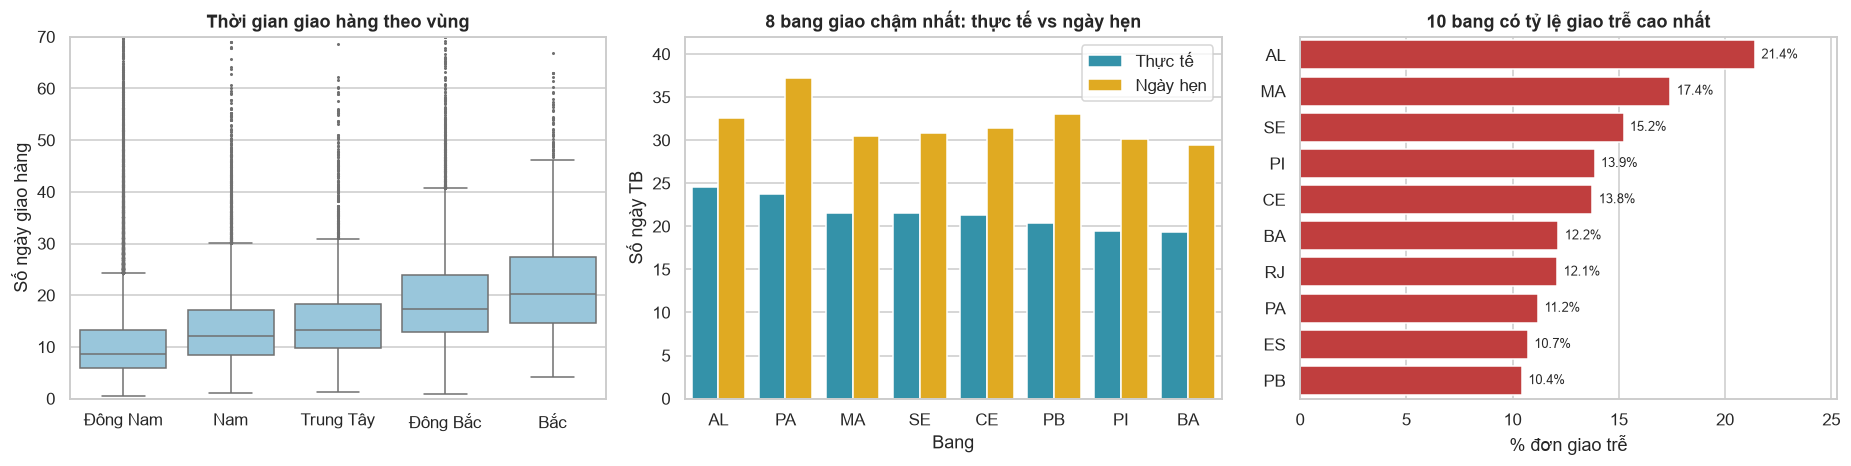

In [21]:
vung_tab = (dd.groupby("region")
              .agg(so_don=("order_id", "count"), giao_tb=("delivery_days", "mean"), giao_trung_vi=("delivery_days", "median"),
                   hen_tb=("estimated_days", "mean"), ty_le_tre_pct=("is_late", lambda s: s.mean() * 100),
                   phi_ship_tb=("freight_value", "mean"), gia_tri_tb=("item_value", "mean"))
              .assign(phi_ship_tren_gia_pct=lambda d: d.phi_ship_tb / d.gia_tri_tb * 100)
              .sort_values("giao_tb"))
vung_tab.to_csv(f"{OUT_TAB}/13_giao_hang_theo_vung.csv", encoding="utf-8-sig")
display(vung_tab.round(1))
KQ["vung"] = [[k, int(v.so_don), round(float(v.giao_tb), 1), round(float(v.ty_le_tre_pct), 1), round(float(v.phi_ship_tb), 1)] for k, v in vung_tab.iterrows()]

# theo bang (lọc bang >= 300 đơn để số liệu đủ tin cậy)
bang = (dd.groupby("customer_state")
          .agg(so_don=("order_id", "count"), thuc_te=("delivery_days", "mean"), du_kien=("estimated_days", "mean"),
               ty_le_tre_pct=("is_late", lambda s: s.mean() * 100), doanh_thu=("item_value", "sum"))
          .query("so_don >= 300").sort_values("thuc_te", ascending=False))
bang.to_csv(f"{OUT_TAB}/14_giao_hang_theo_bang.csv", encoding="utf-8-sig")
cham = bang.head(8)
nhanh = bang.tail(3)
KQ["bang_cham"] = [[k, round(float(v.thuc_te), 1), round(float(v.ty_le_tre_pct), 1)] for k, v in cham.iterrows()]
KQ["bang_nhanh"] = [[k, round(float(v.thuc_te), 1), round(float(v.ty_le_tre_pct), 1)] for k, v in nhanh.iterrows()]
KQ["bang_tre_cao"] = [[k, round(float(v.ty_le_tre_pct), 1)] for k, v in bang.sort_values("ty_le_tre_pct", ascending=False).head(3).iterrows()]
KQ["n_bang_loc"] = int(len(bang))
display(bang.round(1))

# reshape: wide -> long bằng melt để vẽ cột nhóm "thực tế vs dự kiến"
dai = cham[["thuc_te", "du_kien"]].reset_index().melt(id_vars="customer_state", var_name="loai", value_name="so_ngay")
dai["loai"] = dai.loai.map({"thuc_te": "Thực tế", "du_kien": "Ngày hẹn"})

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
order_v = ["Đông Nam", "Nam", "Trung Tây", "Đông Bắc", "Bắc"]
sns.boxplot(data=dd, x="region", y="delivery_days", order=order_v, color="#8ecae6", fliersize=1, ax=ax[0])
ax[0].set_ylim(0, 70); ax[0].set_xlabel(""); ax[0].set_ylabel("Số ngày giao hàng"); ax[0].set_title("Thời gian giao hàng theo vùng")
sns.barplot(data=dai, x="customer_state", y="so_ngay", hue="loai", palette=["#219ebc", "#ffb703"], ax=ax[1])
ax[1].set_ylim(0, 42); ax[1].set_xlabel("Bang"); ax[1].set_ylabel("Số ngày TB"); ax[1].set_title("8 bang giao chậm nhất: thực tế vs ngày hẹn"); ax[1].legend(title="", loc="upper right")
tre = bang.sort_values("ty_le_tre_pct", ascending=False).head(10)
sns.barplot(x=tre.ty_le_tre_pct, y=tre.index, color="#d62828", ax=ax[2])
for i, v in enumerate(tre.ty_le_tre_pct):
    ax[2].text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=8.5)
ax[2].set_xlim(0, tre.ty_le_tre_pct.max() * 1.18)
ax[2].set_xlabel("% đơn giao trễ"); ax[2].set_ylabel(""); ax[2].set_title("10 bang có tỷ lệ giao trễ cao nhất")
plt.tight_layout(); luu_hinh("10_giao_hang_theo_vung_bang"); plt.show()

**Nhận xét theo vùng miền và bang:**
- Thời gian giao và phí ship chênh lệch rõ theo vị trí địa lý. Vùng Đông Nam (tập trung 66.193 đơn, chiếm 68,6% toàn sàn và có phần lớn nhà bán) giao nhanh nhất với trung bình 10,8 ngày và phí ship thấp nhất (19,8 R\$, bằng 15,2% giá hàng). Trong khi đó, vùng Đông Bắc mất trung bình 20,0 ngày (tỷ lệ trễ cao nhất trong 5 vùng: 12,7%) và vùng Bắc mất 22,6 ngày (gấp đôi Đông Nam) với phí ship trung bình 41,3 R\$ (bằng 22,7% giá hàng).
- Xét 21 bang có từ 300 đơn trở lên: bang SP giao nhanh nhất (8,8 ngày, trễ 4,5%), tiếp theo là PR và MG (12,0 ngày). Ngược lại, bang AL giao chậm nhất (24,5 ngày) và có tỷ lệ trễ cao nhất (21,4%), sau đó đến MA (17,4%) và SE (15,2%).

,so_don,doanh_thu,gia_tri_don_tb,phi_ship_tb,diem_danh_gia,ty_le_don_pct,ty_trong_dt_pct
nhom_giao,,,,,,,
<= 7 ngày,26046,"3,134,118.32",120.33,16.87,4.42,27.00,23.71
8-14 ngày,40212,"5,524,488.47",137.38,22.93,4.31,41.68,41.79
15-21 ngày,17713,"2,606,599.13",147.16,26.43,4.14,18.36,19.72
22-30 ngày,7949,"1,194,107.78",150.22,28.91,3.61,8.24,9.03
> 30 ngày,4550,"760,935.23",167.24,30.50,2.25,4.72,5.76


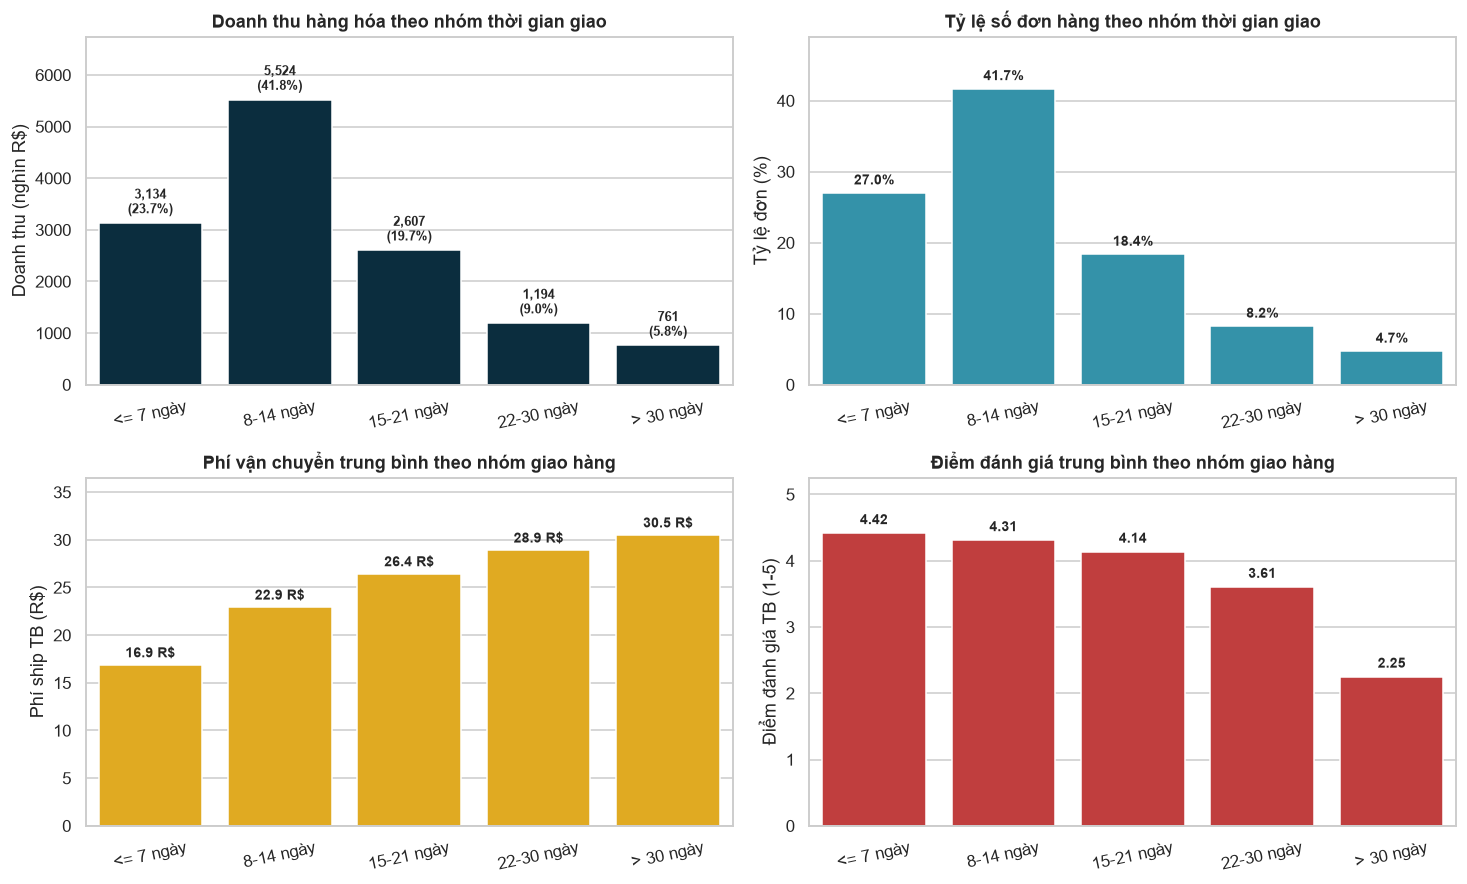

In [22]:
dd["nhom_giao"] = pd.cut(dd.delivery_days, [0, 7, 14, 21, 30, np.inf], labels=["<= 7 ngày", "8-14 ngày", "15-21 ngày", "22-30 ngày", "> 30 ngày"])
nb_ = (dd.groupby("nhom_giao", observed=True)
         .agg(so_don=("order_id", "count"), doanh_thu=("item_value", "sum"), gia_tri_don_tb=("item_value", "mean"),
              phi_ship_tb=("freight_value", "mean"), diem_danh_gia=("review_score", "mean"))
         .assign(ty_le_don_pct=lambda d: d.so_don / d.so_don.sum() * 100,
                 ty_trong_dt_pct=lambda d: d.doanh_thu / d.doanh_thu.sum() * 100))
nb_.to_csv(f"{OUT_TAB}/18_doanh_thu_theo_nhom_thoi_gian_giao.csv", encoding="utf-8-sig")
display(nb_.round(2))
KQ["nhom_giao"] = [[str(k), int(v.so_don), round(float(v.ty_le_don_pct), 1), round(float(v.ty_trong_dt_pct), 1),
                    round(float(v.gia_tri_don_tb), 1), round(float(v.phi_ship_tb), 1), round(float(v.diem_danh_gia), 2)] for k, v in nb_.iterrows()]

fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.2))
ax0, ax1, ax2, ax3 = axes.ravel()

# (1) Doanh thu hàng hóa (nghìn R$) và % doanh thu
dt_k = nb_.doanh_thu / 1e3
sns.barplot(x=nb_.index.astype(str), y=dt_k, color="#023047", ax=ax0)
ax0.set_title("Doanh thu hàng hóa theo nhóm thời gian giao"); ax0.set_ylabel("Doanh thu (nghìn R$)"); ax0.set_ylim(0, dt_k.max() * 1.22)
for i, (v, pct) in enumerate(zip(dt_k, nb_.ty_trong_dt_pct)):
    ax0.text(i, v + 110, f"{v:,.0f}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

# (2) % số đơn hàng
sns.barplot(x=nb_.index.astype(str), y=nb_.ty_le_don_pct, color="#219ebc", ax=ax1)
ax1.set_title("Tỷ lệ số đơn hàng theo nhóm thời gian giao"); ax1.set_ylabel("Tỷ lệ đơn (%)"); ax1.set_ylim(0, 49)
for i, v in enumerate(nb_.ty_le_don_pct):
    ax1.text(i, v + 0.8, f"{v:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")

# (3) Phí ship trung bình (R$)
sns.barplot(x=nb_.index.astype(str), y=nb_.phi_ship_tb, color="#ffb703", ax=ax2)
ax2.set_title("Phí vận chuyển trung bình theo nhóm giao hàng"); ax2.set_ylabel("Phí ship TB (R$)"); ax2.set_ylim(0, 36.5)
for i, v in enumerate(nb_.phi_ship_tb):
    ax2.text(i, v + 0.5, f"{v:.1f} R$", ha="center", va="bottom", fontsize=9, fontweight="bold")

# (4) Điểm đánh giá trung bình (1-5)
sns.barplot(x=nb_.index.astype(str), y=nb_.diem_danh_gia, color="#d62828", ax=ax3)
ax3.set_title("Điểm đánh giá trung bình theo nhóm giao hàng"); ax3.set_ylabel("Điểm đánh giá TB (1-5)"); ax3.set_ylim(0, 5.25)
for i, v in enumerate(nb_.diem_danh_gia):
    ax3.text(i, v + 0.09, f"{v:.2f}", ha="center", va="bottom", fontsize=9, fontweight="bold")

for a in (ax0, ax1, ax2, ax3):
    a.set_xlabel(""); a.tick_params(axis="x", rotation=12)
plt.tight_layout(); luu_hinh("14_nhom_thoi_gian_giao"); plt.show()

**Nhận xét doanh số theo nhóm thời gian giao hàng:**
- Có 68,7% số đơn hoàn tất giao nhận trong 14 ngày đầu (27,0% trong <= 7 ngày và 41,7% từ 8 - 14 ngày), mang lại 65,5% tổng doanh thu hàng hóa (trong đó nhóm 8 - 14 ngày dẫn đầu cả về số đơn lẫn doanh thu với 5,52 triệu R\$, chiếm 41,8%).
- Các nhóm đơn giao lâu hơn (22 - 30 ngày và > 30 ngày) có giá trị đơn trung bình cao hơn (150,2 - 167,2 R\$ so với 120,3 R\$ ở nhóm <= 7 ngày) và phí ship trung bình tăng gần gấp đôi (28,9 - 30,5 R\$ so với 16,9 R\$), do đây thường là các đơn đi bang xa hoặc hàng cồng kềnh. Đổi lại, điểm đánh giá trung bình giảm mạnh từ 4,42 sao (<= 7 ngày) xuống còn 2,25 sao (> 30 ngày).

purchase_month,2017-01-01,2017-02-01,2017-03-01,2017-04-01,2017-05-01,2017-06-01,2017-07-01,2017-08-01,2017-09-01,2017-10-01,2017-11-01,2017-12-01,2018-01-01,2018-02-01,2018-03-01,2018-04-01,2018-05-01,2018-06-01,2018-07-01,2018-08-01
so_don,750.00,"1,653.00","2,546.00","2,303.00","3,545.00","3,135.00","3,872.00","4,193.00","4,150.00","4,478.00","7,288.00","5,513.00","7,069.00","6,555.00","7,003.00","6,798.00","6,749.00","6,096.00","6,156.00","6,351.00"
giao_tb,12.60,13.20,13.00,14.90,11.30,12.00,11.60,11.10,11.90,11.90,15.20,15.40,14.10,16.90,16.30,11.50,11.40,9.20,9.00,7.70
ty_le_tre_pct,2.90,3.00,4.60,6.60,3.00,3.00,2.80,2.90,4.40,4.20,12.40,7.50,5.70,14.10,19.00,4.50,6.60,1.20,3.40,6.20


Tháng trễ nhiều nhất: 03/2018 19.0%


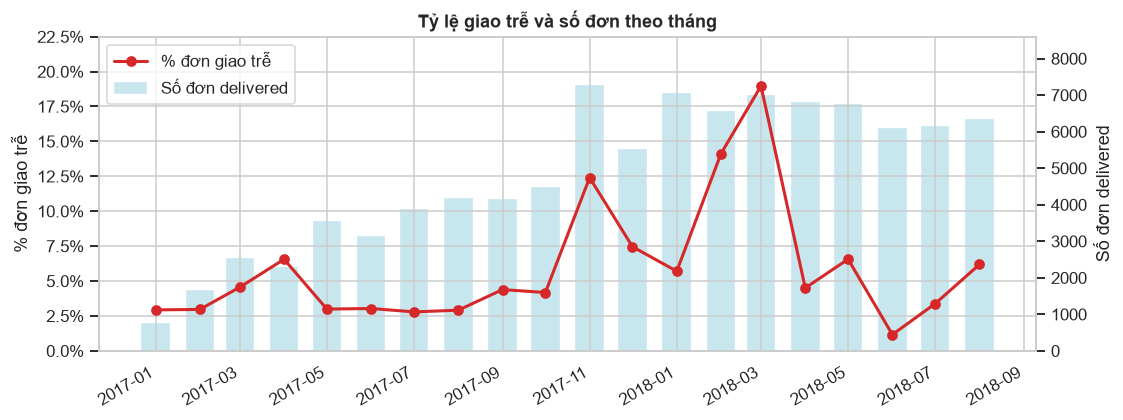

In [23]:
late_m = (dd.groupby("purchase_month")
            .agg(so_don=("order_id", "count"), giao_tb=("delivery_days", "mean"), ty_le_tre_pct=("is_late", lambda s: s.mean() * 100))
            .loc["2017-01-01":"2018-08-01"])
late_m.round(2).to_csv(f"{OUT_TAB}/15_giao_tre_theo_thang.csv", encoding="utf-8-sig")
display(late_m.round(1).T)
thang_tre = late_m.ty_le_tre_pct.idxmax()
KQ.update({"thang_tre_nhat": thang_tre.strftime("%m/%Y"), "tre_nhat_pct": round(float(late_m.ty_le_tre_pct.max()), 1),
           "tre_thang_thap_pct": round(float(late_m.ty_le_tre_pct.min()), 1),
           "tre_thang_thap": late_m.ty_le_tre_pct.idxmin().strftime("%m/%Y"),
           "tre_11_2017": round(float(late_m.loc[pd.Timestamp("2017-11-01"), "ty_le_tre_pct"]), 1),
           "tre_03_2018": round(float(late_m.loc[pd.Timestamp("2018-03-01"), "ty_le_tre_pct"]), 1)})
print("Tháng trễ nhiều nhất:", thang_tre.strftime("%m/%Y"), f"{late_m.ty_le_tre_pct.max():.1f}%")

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(late_m.index, late_m.ty_le_tre_pct, marker="o", color="#d62828", lw=2, label="% đơn giao trễ")
ax.set_ylabel("% đơn giao trễ"); ax.set_ylim(0, 22.5); ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2 = ax.twinx()
ax2.bar(late_m.index, late_m.so_don, width=20, alpha=.25, color="#219ebc", label="Số đơn delivered")
ax2.set_ylabel("Số đơn delivered"); ax2.set_ylim(0, 8600); ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")
ax.set_title("Tỷ lệ giao trễ và số đơn theo tháng"); ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
fig.autofmt_xdate(); luu_hinh("11_giao_tre_theo_thang"); plt.show()

**Nhận xét tỷ lệ giao trễ theo tháng:**
Tỷ lệ giao trễ thường nằm trong khoảng 3% - 6%, nhưng tăng cao vào hai giai đoạn: tháng 11/2017 (12,4%) khi lượng đơn Black Friday tăng mạnh, và hai tháng 02/2018 (14,1%) - 03/2018 (19,0%). Riêng tháng 03/2018 lượng đơn không tăng thêm so với tháng 01/2018 nhưng tỷ lệ trễ vẫn lên gần 1/5 tổng số đơn, cho thấy có sự cố vận chuyển thực tế vào đầu năm 2018. Từ tháng 06/2018, tỷ lệ trễ giảm mạnh xuống thấp nhất còn 1,2% và thời gian giao trung bình rút xuống dưới 9 ngày.

,so_don,diem_tb,ty_le_1_2_sao
nhom_tre,,,
Đúng/sớm hạn,89443,4.29,9.27
Trễ 1-3 ngày,1852,3.29,32.13
Trễ 4-7 ngày,1748,2.10,67.68
Trễ > 7 ngày,2781,1.70,79.29


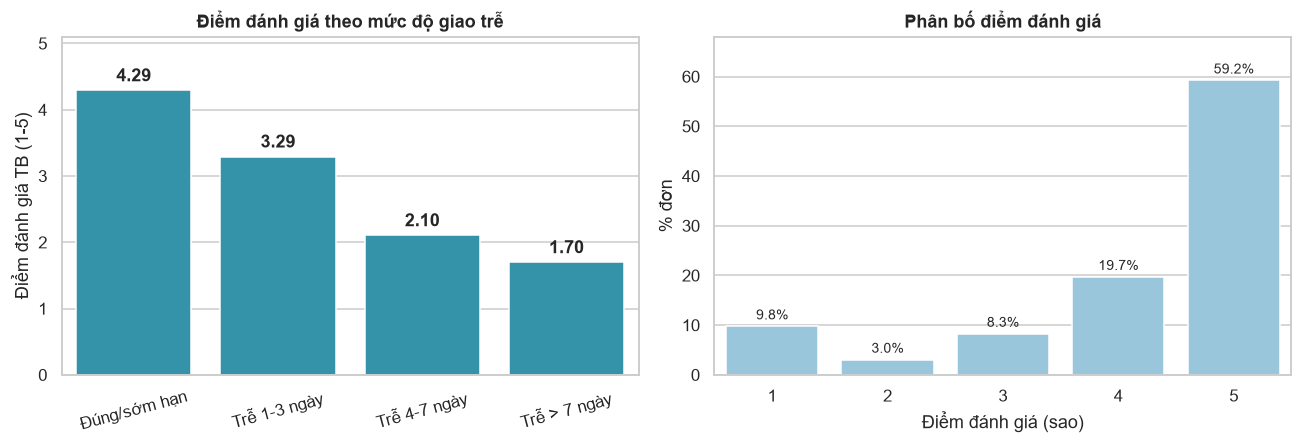

In [24]:
rv = dd.dropna(subset=["review_score"]).copy()
rv["nhom_tre"] = pd.cut(rv.delay_days, [-np.inf, 0, 3, 7, np.inf], labels=["Đúng/sớm hạn", "Trễ 1-3 ngày", "Trễ 4-7 ngày", "Trễ > 7 ngày"])
rt = (rv.groupby("nhom_tre", observed=True)
        .agg(so_don=("order_id", "count"), diem_tb=("review_score", "mean"), ty_le_1_2_sao=("review_score", lambda s: (s <= 2).mean() * 100)))
rt.to_csv(f"{OUT_TAB}/16_diem_danh_gia_theo_do_tre.csv", encoding="utf-8-sig")
display(rt.round(2))
KQ["rv"] = [[str(k), int(v.so_don), round(float(v.diem_tb), 2), round(float(v.ty_le_1_2_sao), 1)] for k, v in rt.iterrows()]
KQ["diem_tb_chung"] = round(float(rv.review_score.mean()), 2)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sns.barplot(data=rt.reset_index(), x="nhom_tre", y="diem_tb", color="#219ebc", ax=ax[0])
for i, v in enumerate(rt.diem_tb):
    ax[0].text(i, v + 0.08, f"{v:.2f}", ha="center", va="bottom", fontweight="bold")
ax[0].set_ylim(0, 5.1); ax[0].set_xlabel(""); ax[0].set_ylabel("Điểm đánh giá TB (1-5)"); ax[0].set_title("Điểm đánh giá theo mức độ giao trễ")
ax[0].tick_params(axis="x", rotation=15)
dist = rv.review_score.value_counts(normalize=True).sort_index() * 100
sns.barplot(x=dist.index.astype(int), y=dist.values, color="#8ecae6", ax=ax[1])
for i, v in enumerate(dist.values):
    ax[1].text(i, v + 0.8, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
ax[1].set_ylim(0, 68); ax[1].set_xlabel("Điểm đánh giá (sao)"); ax[1].set_ylabel("% đơn"); ax[1].set_title("Phân bố điểm đánh giá")
plt.tight_layout(); luu_hinh("12_danh_gia_theo_do_tre"); plt.show()

**Nhận xét mối liên hệ giữa giao trễ và điểm đánh giá:**
Điểm đánh giá chung toàn sàn đạt trung bình 4,16 / 5 sao (59,2% đơn đạt 5 sao). Khi tách theo mức độ trễ hạn, điểm trung bình giảm rất rõ: đơn giao đúng hoặc sớm hạn đạt 4,29 sao (chỉ 9,3% bị 1 - 2 sao); trễ 1 - 3 ngày giảm còn 3,29 sao (32,1% bị 1 - 2 sao); trễ 4 - 7 ngày còn 2,10 sao (67,7% bị 1 - 2 sao); và trễ hơn 7 ngày chỉ còn 1,70 sao với 79,3% khách đánh giá 1 - 2 sao. Lưu ý đây là mối liên hệ quan sát được từ thống kê mô tả, chưa khẳng định quan hệ nhân quả tuyệt đối vì đơn giao chậm cũng có thể kèm các vấn đề khác về hàng hóa.

,so_don,doanh_thu,phi_ship,aov,ty_trong_pct,ship_tren_gia_pct
customer_state,,,,,,
SP,40501,"5,067,633.20","702,070.00",125.10,38.30,13.90
RJ,12350,"1,759,651.10","295,750.40",142.50,13.30,16.80
MG,11354,"1,552,481.80","266,409.80",136.70,11.70,17.20
RS,5345,"728,897.50","132,575.30",136.40,5.50,18.20
PR,4923,"666,063.50","115,645.30",135.30,5.00,17.40
SC,3546,"507,012.10","88,115.60",143.00,3.80,17.40
BA,3256,"493,584.10","97,553.70",151.60,3.70,19.80
DF,2080,"296,498.40","49,624.90",142.50,2.20,16.70


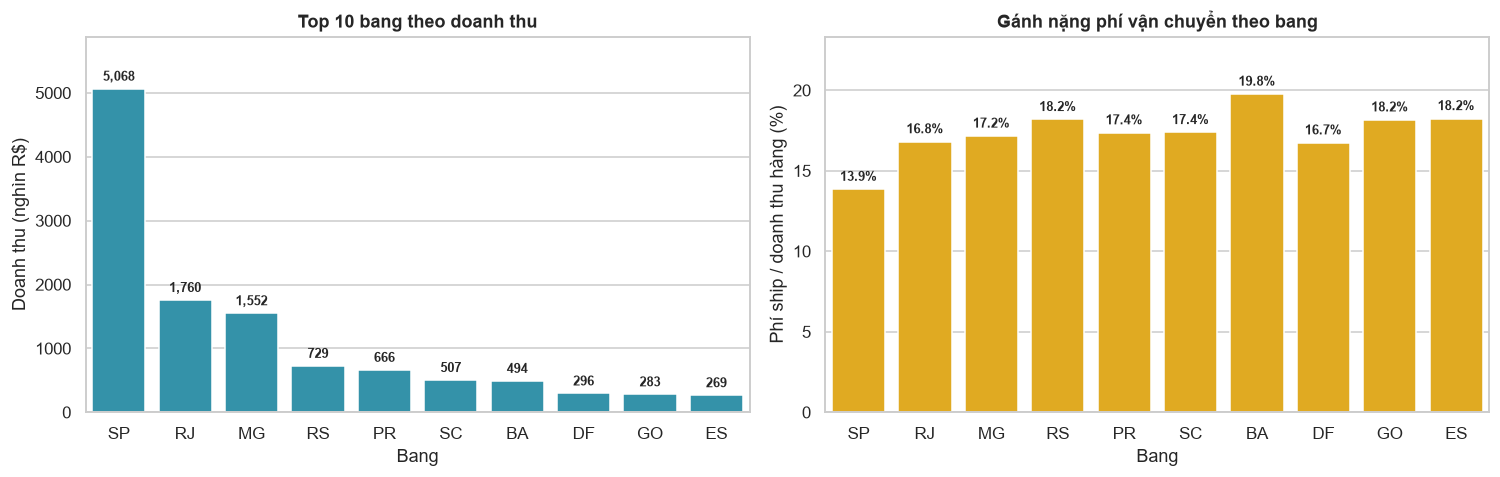

In [25]:
bang_dt = (dlv.groupby("customer_state")
              .agg(so_don=("order_id", "count"), doanh_thu=("item_value", "sum"), phi_ship=("freight_value", "sum"),
                   aov=("item_value", "mean"))
              .assign(ty_trong_pct=lambda d: d.doanh_thu / d.doanh_thu.sum() * 100,
                      ship_tren_gia_pct=lambda d: d.phi_ship / d.doanh_thu * 100)
              .sort_values("doanh_thu", ascending=False))
bang_dt.to_csv(f"{OUT_TAB}/17_doanh_thu_theo_bang.csv", encoding="utf-8-sig")
display(bang_dt.head(8).round(1))
KQ["bang_dt"] = [[k, round(float(v.doanh_thu), 0), round(float(v.ty_trong_pct), 1), round(float(v.ship_tren_gia_pct), 1)] for k, v in bang_dt.head(5).iterrows()]
KQ["sp_pct"] = round(float(bang_dt.loc["SP", "ty_trong_pct"]), 1)
KQ["top3_bang_pct"] = round(float(bang_dt.ty_trong_pct.head(3).sum()), 1)
KQ["ship_tb_pct"] = round(float(dlv.freight_value.sum() / dlv.item_value.sum() * 100), 1)

t10 = bang_dt.head(10)
fig, ax = plt.subplots(1, 2, figsize=(13.8, 4.5))
dt_k = t10.doanh_thu / 1e3
sns.barplot(x=t10.index, y=dt_k, color="#219ebc", ax=ax[0])
for i, v in enumerate(dt_k):
    ax[0].text(i, v + 80, f"{v:,.0f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
ax[0].set_ylim(0, dt_k.max() * 1.16)
ax[0].set_xlabel("Bang"); ax[0].set_ylabel("Doanh thu (nghìn R$)"); ax[0].set_title("Top 10 bang theo doanh thu")

sns.barplot(x=t10.index, y=t10.ship_tren_gia_pct, color="#ffb703", ax=ax[1])
for i, v in enumerate(t10.ship_tren_gia_pct):
    ax[1].text(i, v + 0.35, f"{v:.1f}%", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
ax[1].set_ylim(0, t10.ship_tren_gia_pct.max() * 1.18)
ax[1].set_xlabel("Bang"); ax[1].set_ylabel("Phí ship / doanh thu hàng (%)"); ax[1].set_title("Gánh nặng phí vận chuyển theo bang")
plt.tight_layout(); luu_hinh("13_doanh_thu_phi_ship_theo_bang"); plt.show()

**Nhận xét doanh thu và phí ship theo bang:**
Doanh thu tập trung mạnh ở khu vực Đông Nam: riêng bang SP chiếm 38,3% tổng doanh thu toàn sàn (5,07 triệu R\$), còn 3 bang dẫn đầu (SP, RJ, MG) cộng lại chiếm 63,4%. Tỷ lệ phí vận chuyển trên doanh thu hàng hóa trung bình toàn sàn là 16,6%, thấp nhất ở SP (13,9%) và tăng lên khoảng 18% - 20% ở các bang xa hơn như RS (18,2%), GO (18,2%), ES (18,2%) và BA (19,8%).

## 10. Lưu dữ liệu đã xử lý và các bảng kết quả
Xuất 2 tệp dữ liệu đã làm sạch (`du_lieu_xu_ly/`), 18 bảng kết quả CSV cùng tệp chỉ số tổng hợp JSON (`bang_ket_qua/`), và 14 biểu đồ PNG 150 DPI (`hinh/`).

In [26]:
cols = ["order_id", "customer_unique_id", "customer_state", "region", "order_status", "order_purchase_timestamp",
        "order_delivered_customer_date", "order_estimated_delivery_date", "n_items", "item_value", "freight_value",
        "gmv", "payment_value", "main_payment_type", "max_installments", "delivery_days", "estimated_days", "delay_days",
        "is_late", "valid_delivery", "review_score"]
dlv[cols].to_csv(f"{OUT_DATA}/olist_don_hang_delivered_da_xu_ly.csv", index=False, encoding="utf-8-sig")
di[["order_id", "order_item_id", "product_id", "category_en", "category_vi", "price", "freight_value", "purchase_month"]].to_csv(
    f"{OUT_DATA}/olist_san_pham_trong_don_delivered.csv", index=False, encoding="utf-8-sig")

KQ["log"] = log_df.values.tolist()
KQ["tong_quan"] = tong_quan.reset_index().values.tolist()
KQ["so_don_xu_ly"] = int(len(dlv))
with open(f"{OUT_TAB}/chi_so_chinh.json", "w", encoding="utf-8") as f:
    json.dump(KQ, f, ensure_ascii=False, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Đã lưu dữ liệu xử lý, bảng kết quả, hình và chỉ số chính.")
print(sorted(os.listdir(OUT_FIG)))

Đã lưu dữ liệu xử lý, bảng kết quả, hình và chỉ số chính.
['01_ngoai_le_so_tien.png', '02_trang_thai_don.png', '03_doanh_thu_theo_thang.png', '04_thu_gio_dat_hang.png', '05_nganh_hang_top10_pareto.png', '06_top5_nganh_theo_thang.png', '07_phuong_thuc_thanh_toan.png', '08_tra_gop_va_co_cau_theo_thang.png', '09_thoi_gian_giao_hang.png', '10_giao_hang_theo_vung_bang.png', '11_giao_tre_theo_thang.png', '12_danh_gia_theo_do_tre.png', '13_doanh_thu_phi_ship_theo_bang.png', '14_nhom_thoi_gian_giao.png']


## 11. Kết luận
- Về xử lý và kết hợp dữ liệu đa bảng: bài đã sử dụng 7/9 bảng của bộ dữ liệu Olist, mô tả rõ khóa chính/khóa ngoại và kiểm chứng bằng thực nghiệm rằng nối trực tiếp các bảng 1 - N làm tăng thêm 18.936 dòng nhân bản và làm tổng `payment_value` sai lệch +28,16%. Quy trình gộp theo đơn hàng trước khi nối kèm `validate` và `assert` giúp giữ nguyên 99.441 đơn gốc, với tỷ lệ khớp tiền hàng và tiền thanh toán trên tập đơn `delivered` đạt 99,60%.
- Về kết quả phân tích doanh số và vận hành:
  1. Theo tháng: doanh thu 8 tháng đầu năm 2018 tăng +141,1% so với cùng kỳ 2017 nhờ mở rộng số lượng đơn (giá trị đơn trung bình ổn định khoảng 137 R\$), đạt đỉnh vào 11/2017 (987.765 R\$, dịp Black Friday), và 81,5% đơn phát sinh trong khung 10h - 22h các ngày trong tuần.
  2. Theo nhóm hàng: 18/74 ngành hàng đầu tiên tạo ra 80% doanh thu (Pareto), dẫn đầu là Sức khỏe & làm đẹp (9,3%), Đồng hồ & quà tặng (8,8%) và Giường - bàn - phòng tắm (7,7%).
  3. Theo phương thức thanh toán: thẻ tín dụng chiếm 75,4% số đơn và 78,4% tổng tiền; 67,9% đơn thẻ sử dụng trả góp, trong đó số kỳ trả góp tăng dần theo giá trị đơn (từ 100,5 R\$ ở nhóm 1 kỳ lên 333,5 R\$ ở nhóm 7 - 10 kỳ).
  4. Theo thời gian giao hàng và vận chuyển: thời gian giao trung bình 12,6 ngày (riêng chặng vận chuyển chiếm 74%), 68,7% số đơn (65,5% doanh thu) hoàn tất trong 14 ngày đầu. Tỷ lệ giao trễ chung là 6,77% nhưng chênh lệch lớn giữa các vùng (Đông Nam 10,8 ngày so với vùng Bắc 22,6 ngày), và giao trễ gắn liền với việc điểm đánh giá giảm từ 4,29 xuống 1,70 sao.